# Bulgaria 2025 Article IV: reading an IMF staff report with an LLM pipeline

**Report:** IMF Country Report No. 25/306, *Bulgaria: 2025 Article IV Consultation, Press Release; Staff Report; and Staff Supplement* (66 PDF pages; staff report completed 3 November 2025, supplement 11 November 2025). Allocation: Bulgaria, 2024-2025.

The notebook works on tables. Every stage takes a pandas DataFrame and returns a new one: pages, then sections, then chunks, then summaries, claims and answers. The language work runs on two Gemini Flash models through the Gemini API. The **writer**, `gemini-3.6-flash`, summarises, extracts and answers. The **judge**, `gemini-3.5-flash-lite`, is a different and smaller model that marks the writer's output against the source text, with its own instructions and temperature 0. A judge can still be lenient, so every judge verdict sits next to a check done in code (numbers in the source, quotes on their page, table cells, gold pages). Retrieval uses `gtr-t5-base` sentence embeddings in a FAISS `IndexFlatL2`.

| Part | Brief task | Files written to `artefacts/` |
|---|---|---|
| 0 | setup, prompts, model layer | `run_settings.json` |
| 1 | Task 1: extraction, cleaning, sections, chunks, summaries, judge | `pages.json`, `sections.json`, `chunks.json`, `section_summaries.json`, `executive_summary.json` |
| 2 | Task 2: themes, strengths and vulnerabilities, indicators, audit, time series | `theme_counts.json`, `strengths_vulnerabilities.json`, `indicators.json`, `indicator_audit.json`, `time_series.json` |
| 3 | Task 3: FAISS retrieval and grounded answers | `rag_answers.json` |
| 4 | Extension: multi-query retrieval against a single query | `multiquery_vs_single.json` |
| 5 | Task 4: `pd.melt` and the dashboard | `long_tables.json`, `figures/*.png` (300 dpi) |
| 6 | run record for the written report | `call_ledger.json`, `prompt_book.json`, `hand_checks.json` |

**Running it.** Put the repository folder in Colab (or clone it) so that `data/` and `cache/` sit next to the notebook, then choose *Runtime > Run all*. New model calls need a Gemini API key saved as a Colab secret; the secret's name is `key_secret` in the settings below. Every reply is stored in `cache/replies.zip`, so a rerun replays the stored replies and makes no model calls; outside Colab the notebook runs from that archive alone.

## Part 0. Setup

Colab already has pandas, matplotlib, sentence-transformers, pydantic, Jinja2 and PyYAML. Only `pypdf` and `faiss-cpu` are installed here. Both are pinned: a different pypdf release can extract slightly different text, which would change the prompts and miss the cache.

In [1]:
!pip -q install "pypdf==6.21.4" "faiss-cpu==1.15.1"

### 0.1 Settings

All settings are in one YAML block, read into a frozen Pydantic model. A typo in a key or a value of the wrong type fails here, not halfway through a model run. The only outside override is the environment variable `BG_BACKEND`, which can force `replay` (cache only).

*Design note:* chunk length is 340 tokens counted with the embedder's own SentencePiece tokenizer. GTR reads up to 512 tokens, so a chunk is never cut by the encoder. The brief asks for roughly 300 to 500 tokens with 50 tokens of overlap.

In [2]:
import hashlib
import json
import os
import re
import textwrap
import time
import zipfile
from pathlib import Path
from typing import Literal, Optional

import jinja2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import yaml
from pydantic import BaseModel, ConfigDict, Field, ValidationError, create_model

CONFIG_YAML = """
report:
  pdf: data/IMF_CR_25_306_Bulgaria_2025_Article_IV.pdf
  country: Bulgaria
  label: IMF Country Report No. 25/306, 2025 Article IV Consultation
  printed_page_offset: 4        # printed page 4 of the staff report is PDF page 8
models:
  backend: gemini_api           # gemini_api (a Gemini API key) | colab_ai (Colab's built-in AI) | replay (cache only)
  key_secret: GEMINI_FREE_KEY   # name of the Colab secret that holds the key, used only by gemini_api
  writer: gemini-3.6-flash      # summaries, extraction, answers
  judge: gemini-3.5-flash-lite  # a different, smaller Flash model; own instructions, temperature 0
  temperature: 0.1              # writer
  judge_temperature: 0.0
  max_output_tokens: 16384      # the Flash writer thinks before it answers, and the thinking counts here
  attempts: 6                   # a rate limit (429) or a server error (503) is retried with longer pauses
retrieval:
  embedder: sentence-transformers/gtr-t5-base
  reranker: cross-encoder/ms-marco-MiniLM-L-6-v2
  chunk_tokens: 340
  overlap_tokens: 50
  top_k: 6
  paraphrases: 3
limits:
  summary_words: 100            # every section summary must stay under this
  min_items: 5                  # bullets, strengths and vulnerabilities: 5 to 7 each
  max_items: 7
paths:
  out: artefacts
  cache: cache/replies.zip
"""


class Frozen(BaseModel):
    model_config = ConfigDict(frozen=True, extra="forbid")


class ReportCfg(Frozen):
    pdf: str
    country: str
    label: str
    printed_page_offset: int


class ModelCfg(Frozen):
    backend: Literal["gemini_api", "colab_ai", "replay"]
    key_secret: str
    writer: str
    judge: str
    temperature: float
    judge_temperature: float
    max_output_tokens: int
    attempts: int


class RetrievalCfg(Frozen):
    embedder: str
    reranker: str
    chunk_tokens: int = Field(ge=300, le=500)
    overlap_tokens: int
    top_k: int
    paraphrases: int


class LimitCfg(Frozen):
    summary_words: int
    min_items: int
    max_items: int


class PathCfg(Frozen):
    out: str
    cache: str


class Settings(Frozen):
    report: ReportCfg
    models: ModelCfg
    retrieval: RetrievalCfg
    limits: LimitCfg
    paths: PathCfg


raw = yaml.safe_load(CONFIG_YAML)
if os.environ.get("BG_BACKEND"):
    raw["models"]["backend"] = os.environ["BG_BACKEND"]
CFG = Settings.model_validate(raw)

OUT = Path(CFG.paths.out)
(OUT / "figures").mkdir(parents=True, exist_ok=True)
Path(CFG.paths.cache).parent.mkdir(parents=True, exist_ok=True)
PDF = Path(CFG.report.pdf)
assert PDF.is_file(), f"{PDF} is missing: the data/ folder must sit next to this notebook"
PDF_SHA256 = hashlib.sha256(PDF.read_bytes()).hexdigest()


def save(name: str, obj) -> Path:
    """Write one artefact as JSON. DataFrames become lists of records; NaN becomes null."""
    if isinstance(obj, pd.DataFrame):
        obj = json.loads(obj.to_json(orient="records", force_ascii=False))
    path = OUT / f"{name}.json"
    path.write_text(json.dumps(obj, indent=2, ensure_ascii=False, default=str), encoding="utf-8")
    return path


save("run_settings", CFG.model_dump() | {"pdf_sha256": PDF_SHA256})
print(f"{PDF.name}  sha256 {PDF_SHA256[:16]}")
print(f"writer {CFG.models.writer} | judge {CFG.models.judge} | embedder {CFG.retrieval.embedder}")

IMF_CR_25_306_Bulgaria_2025_Article_IV.pdf  sha256 b65242d477a5d090
writer gemini-3.6-flash | judge gemini-3.5-flash-lite | embedder sentence-transformers/gtr-t5-base


### 0.2 Prompts as templates

Every prompt is a Jinja2 template in one dictionary, `PROMPTS`. Each entry has a system instruction and a user template. `StrictUndefined` turns a missing variable into an error, so a prompt is never sent with an empty slot. The whole dictionary is saved at the end of the run, so the report quotes the prompts that were actually used.

Three choices recur in the prompts:
- the writer receives only the text it is about, with PDF page labels, and is told to use nothing else;
- every number in a reply must appear in that text (the code checks this afterwards as well);
- the judge receives the same source text as the writer and must name a concrete fault before it may give less than 5.

In [3]:
PROMPTS = {
    "section_summary": {
        "system": "You are an economist at a finance ministry summarising one part of an IMF staff report for colleagues. "
                  "Use only the text supplied. Never add numbers, dates or claims that are not in it.",
        "user": textwrap.dedent("""\
            Summarise the part of the report titled "{{ title }}" (PDF pages {{ pages }}).
            Rules:
            - one paragraph of {{ low }} to {{ high }} words, never {{ cap }} or more;
            - lead with the main finding, then the figures that support it, then what IMF staff recommend if the text recommends anything;
            - copy every number exactly as printed, with its unit and year;
            - no opening such as "This section"; no closing generalities.
            {% if feedback %}A reviewer found these faults in your earlier draft. Fix every one:
            {{ feedback }}
            {% endif %}
            TEXT:
            {{ text }}"""),
    },
    "summary_judge": {
        "system": "You check summaries of IMF reports for a central bank research unit. You are strict and specific.",
        "user": textwrap.dedent("""\
            Compare the SUMMARY with the SOURCE and give three scores from 1 (poor) to 5 (no fault):
            - consistency: the summary does not contradict the source and does not mix up years, units or directions of change;
            - completeness: the main finding and the main supporting facts of the source are present;
            - factual_alignment: every number and claim in the summary can be found in the source.
            List each fault you find as one short sentence that quotes the summary words at fault.
            A score below 5 must be explained by at least one listed fault.
            SOURCE ({{ title }}, PDF pages {{ pages }}):
            {{ text }}

            SUMMARY:
            {{ summary }}"""),
    },
    "executive_summary": {
        "system": "You brief a financial stability committee. Use only the section summaries supplied.",
        "user": textwrap.dedent("""\
            From the section summaries of the IMF's 2025 Article IV report on {{ country }}, write {{ low }} to {{ high }} bullets
            on financial stability findings and the risk assessment. Each bullet: one sentence, one finding, at least one figure
            copied from the summaries, and the id of the section it comes from (for example S07).
            Cover the banking sector, credit and housing, public finances, inflation and the main risks to the outlook.
            {% if note %}A reviewer rejected some bullets of your first set. Correct or replace them:
            {{ note }}
            {% endif %}SECTION SUMMARIES:
            {% for s in summaries %}[{{ s.section_id }}] {{ s.title }}: {{ s.summary }}
            {% endfor %}"""),
    },
    "executive_judge": {
        "system": "You check briefing notes against their sources. You are strict and specific.",
        "user": textwrap.dedent("""\
            Check each BULLET against the SECTION SUMMARIES it was written from. For each bullet say whether it is
            supported (true or false) and give the reason in one sentence. Then score the whole set from 1 to 5 for
            consistency, completeness (does it cover banks, credit and housing, public finances, inflation and risks?)
            and factual_alignment.
            SECTION SUMMARIES:
            {% for s in summaries %}[{{ s.section_id }}] {{ s.summary }}
            {% endfor %}
            BULLETS:
            {% for b in bullets %}{{ loop.index }}. ({{ b.section_id }}) {{ b.text }}
            {% endfor %}"""),
    },
    "theme_labels": {
        "system": "You classify passages of an IMF staff report by macro-financial theme.",
        "user": textwrap.dedent("""\
            For each passage, choose the ONE theme it is mainly about, or "none" if it is about none of them.
            Themes: {{ themes | join("; ") }}.
            Also list any other themes the passage discusses in more than a passing word.
            {% for c in chunks %}<<{{ c.chunk_id }}>>
            {{ c.text }}
            {% endfor %}"""),
    },
    "strengths_vulnerabilities": {
        "system": "You are a sovereign risk analyst. Every point must rest on a sentence of the report supplied.",
        "user": textwrap.dedent("""\
            From the IMF staff report text below, list {{ low }} to {{ high }} strengths or growth drivers of {{ country }}'s economy
            and {{ low }} to {{ high }} vulnerabilities. For each point give a short label, one explanatory sentence, the PDF page,
            and a quote of 8 to 30 words copied character for character from that page.
            TEXT (page labels in brackets):
            {{ text }}"""),
    },
    "sv_judge": {
        "system": "You check analyst notes against an IMF report. You are strict and specific.",
        "user": textwrap.dedent("""\
            For each POINT, read the QUOTE and the PAGE TEXT it comes from. Decide whether the point is supported by
            the page (true or false) and whether it is correctly classed as a strength or a vulnerability. Give a
            one-sentence reason.
            {% for p in points %}POINT {{ loop.index }} [{{ p.kind }}] {{ p.label }}: {{ p.explanation }}
            QUOTE: "{{ p.quote }}"
            PAGE {{ p.page }} TEXT: {{ p.page_text }}

            {% endfor %}"""),
    },
    "indicators": {
        "system": "You extract macro-financial indicators from IMF tables. Use only the pages supplied.",
        "user": textwrap.dedent("""\
            Fill the indicator record for {{ country }} from the IMF pages below. All values are percentages.
            - gdp_growth_forecast_pct: real GDP growth for the current-year projection {{ year }};
            - headline_inflation_rate_pct: headline consumer price inflation, annual average, {{ year }};
            - central_bank_policy_rate_pct: the policy interest rate set by the national central bank;
            - non_performing_loan_ratio: nonperforming loans to total gross loans, latest year shown;
            - unemployment_rate_pct: unemployment rate, {{ year }};
            - tier_1_capital_ratio: Tier 1 capital to risk-weighted assets, latest year shown.
            If a value is not printed in these pages, give null and say why in "reason". Never estimate.
            For every value give the year, the PDF page and the table row label exactly as printed.
            PAGES:
            {{ text }}"""),
    },
    "indicator_audit": {
        "system": "You audit numbers extracted from IMF tables. You are strict.",
        "user": textwrap.dedent("""\
            For each extracted ITEM, look it up in the PAGE TEXT and give a verdict:
            CORRECT (the value is printed for that row and year), WRONG_VALUE, WRONG_YEAR,
            CORRECTLY_NULL (the indicator is really not printed) or WRONGLY_NULL (it is printed).
            Give the value you see in the table, or null, and one sentence of reason.
            {% for it in items %}ITEM {{ it.field }}: value={{ it.value }} year={{ it.year }} page={{ it.page }} row="{{ it.row_label }}" reason="{{ it.reason }}"
            {% endfor %}
            PAGE TEXT:
            {{ text }}"""),
    },
    "time_series": {
        "system": "You turn IMF statistical tables into data. Copy numbers exactly; never fill gaps.",
        "user": textwrap.dedent("""\
            From the table text below, return the rows listed, one value per year shown in the table header.
            Use null where the table prints "..." or nothing. Keep the units of the table.
            Rows: {{ rows | join("; ") }}.
            TABLE (PDF page {{ page }}):
            {{ text }}"""),
    },
    "rag_answer": {
        "system": "You answer questions about an IMF staff report using only the numbered passages supplied. "
                  "If the passages do not contain the answer, say so plainly and do not guess.",
        "user": textwrap.dedent("""\
            QUESTION: {{ question }}
            Answer in at most three sentences. Cite every passage you use by its id in square brackets, for example [C041].
            Set "answerable" to false if the passages do not contain the answer.
            PASSAGES:
            {% for p in passages %}[{{ p.chunk_id }}] (PDF p.{{ p.page }}) {{ p.text }}
            {% endfor %}"""),
    },
    "rag_judge": {
        "system": "You grade answers produced by a retrieval system over an IMF report. You are strict.",
        "user": textwrap.dedent("""\
            QUESTION: {{ question }}
            ANSWER: {{ answer }}
            Score from 1 to 5:
            - faithfulness: every statement in the answer is backed by the passages (a refusal backed by the passages scores 5);
            - completeness: the answer gives everything the question asks for that the REFERENCE contains.
            Explain each score in one sentence.
            REFERENCE (what the report says, written by hand from the PDF): {{ reference }}
            PASSAGES THE SYSTEM SAW:
            {% for p in passages %}[{{ p.chunk_id }}] {{ p.text }}
            {% endfor %}"""),
    },
    "query_variants": {
        "system": "You help a search engine find passages in an IMF staff report.",
        "user": textwrap.dedent("""\
            QUESTION: {{ question }}
            1. Rewrite the question {{ n }} times with different wording an IMF economist might use (other terms, more specific).
            2. Write a short passage (60 to 90 words) in the style of an IMF staff report that would answer the question.
               Invent nothing you would present as fact elsewhere: it is used only as a search probe."""),
    },
}

JINJA = jinja2.Environment(undefined=jinja2.StrictUndefined, trim_blocks=False, autoescape=False)


def render(name: str, **ctx) -> tuple[str, str]:
    entry = PROMPTS[name]
    return entry["system"], JINJA.from_string(entry["user"]).render(**ctx)


print(f"{len(PROMPTS)} prompt templates:", ", ".join(PROMPTS))

13 prompt templates: section_summary, summary_judge, executive_summary, executive_judge, theme_labels, strengths_vulnerabilities, sv_judge, indicators, indicator_audit, time_series, rag_answer, rag_judge, query_variants


### 0.3 Model layer

`ask()` is the only function that talks to a model:
1. It renders the prompt and builds a cache key: a BLAKE2 hash of the model, system text, prompt, reply schema and temperature.
2. If the key is in `cache/replies.zip`, the stored reply is used. Otherwise it calls the backend. It retries a transient error or a per-minute rate limit with growing pauses (10 s up to 90 s). Spent credit or an exhausted cost quota stops at once, because a retry cannot fix it.
3. The reply is parsed into the Pydantic model of that step. If parsing fails, or `check()` finds a rule the schema cannot express, the model gets **one** repair prompt listing the problems.
4. Every call goes into `LEDGER` with its step, role, model, whether it came from the cache, seconds and tokens.

The run uses `gemini_api`: the `google-genai` SDK, with the reply schema enforced by the API. A reply cut off at the output-token limit counts as a failed call and is never stored. A `colab_ai` route (Colab's built-in model proxy through the OpenAI client) is kept as a second option; it has no schema mode, so there the schema is described in the prompt text and the cache key ignores that addition, and `max_tokens` is always set because without it the proxy books the cost of the longest possible reply against the quota.

In [4]:
class Reply(BaseModel):
    model_config = ConfigDict(extra="forbid")


class ReplayMiss(RuntimeError):
    """Raised when a reply is needed but neither the cache nor a backend can give it."""


def secret_key() -> Optional[str]:
    try:
        from google.colab import userdata
        return userdata.get(CFG.models.key_secret)
    except ImportError:          # not on Colab
        return os.environ.get(CFG.models.key_secret)
    except Exception as err:     # secret missing, or access not granted (yet)
        print(f"secret {CFG.models.key_secret} not readable ({type(err).__name__}); only stored replies can be used")
        return os.environ.get(CFG.models.key_secret)


def on_colab() -> bool:
    try:
        from google.colab import ai  # noqa: F401
        return True
    except ImportError:
        return False


def choose_backend(wanted: str) -> str:
    """Off Colab, or without a key for gemini_api, only the stored replies can be used."""
    if wanted == "colab_ai" and not on_colab():
        return "replay"
    if wanted == "gemini_api" and not secret_key():
        return "replay"
    return wanted


BACKEND = choose_backend(CFG.models.backend)


def inline_schema(model: type[BaseModel]) -> dict:
    """Pydantic JSON Schema with every $ref expanded and titles dropped (both API routes read it more reliably)."""
    schema = model.model_json_schema()
    defs = schema.pop("$defs", {})

    def walk(node):
        if isinstance(node, dict):
            if "$ref" in node:
                return walk(defs[node["$ref"].split("/")[-1]])
            return {k: walk(v) for k, v in node.items() if k not in ("title", "default")}
        if isinstance(node, list):
            return [walk(v) for v in node]
        return node
    return walk(schema)


class ReplyStore:
    """Append-only zip archive: one JSON member per cache key."""

    def __init__(self, path: str):
        self.path = Path(path)
        self.items: dict[str, dict] = {}
        if self.path.exists():
            with zipfile.ZipFile(self.path) as zf:
                for name in zf.namelist():
                    self.items[name.removesuffix(".json")] = json.loads(zf.read(name))

    def get(self, key: str):
        return self.items.get(key)

    def put(self, key: str, record: dict) -> None:
        self.items[key] = record
        with zipfile.ZipFile(self.path, "a", compression=zipfile.ZIP_DEFLATED) as zf:
            zf.writestr(f"{key}.json", json.dumps(record, ensure_ascii=False))


STORE = ReplyStore(CFG.paths.cache)
LEDGER: list[dict] = []
_clients: dict = {}


def call_backend(model: str, system: str, prompt: str, schema: dict, temperature: float) -> dict:
    started = time.perf_counter()
    if BACKEND == "gemini_api":
        from google import genai
        from google.genai import types
        if "genai" not in _clients:
            _clients["genai"] = genai.Client(api_key=secret_key())
        client = _clients["genai"]
        resp = client.models.generate_content(
            model=model, contents=prompt,
            config=types.GenerateContentConfig(
                system_instruction=system, temperature=temperature,
                max_output_tokens=CFG.models.max_output_tokens,
                response_mime_type="application/json", response_json_schema=schema))
        if resp.candidates and "MAX_TOKENS" in str(resp.candidates[0].finish_reason):
            raise RuntimeError("the reply was cut off at max_output_tokens")
        use = resp.usage_metadata
        text, tin, tout = resp.text or "", use.prompt_token_count or 0, use.candidates_token_count or 0
    elif BACKEND == "colab_ai":
        from google.colab import ai
        from openai import OpenAI
        client = _clients.setdefault("proxy", OpenAI(base_url=f"{ai._get_model_proxy_host()}/models/openapi",
                                                     api_key=ai._get_model_proxy_token()))
        shaped = prompt + "\n\nReply with one JSON object that follows this JSON Schema, and nothing else:\n" + json.dumps(schema)
        resp = client.chat.completions.create(
            model=f"google/{model}", temperature=temperature, max_tokens=CFG.models.max_output_tokens,
            messages=[{"role": "system", "content": system}, {"role": "user", "content": shaped}])
        text = resp.choices[0].message.content or ""
        tin, tout = (resp.usage.prompt_tokens, resp.usage.completion_tokens) if resp.usage else (0, 0)
    else:
        raise ReplayMiss(f"no stored reply for this prompt and no backend: run on Colab or add the {CFG.models.key_secret} secret")
    return {"text": text, "seconds": round(time.perf_counter() - started, 2), "tokens_in": int(tin), "tokens_out": int(tout)}


FATAL = re.compile(r"prepay|credit|billing|exceeds available quota|PERMISSION_DENIED|API key not valid", re.I)


def fetch(step: str, role: str, model: str, system: str, prompt: str, schema: dict) -> dict:
    temperature = CFG.models.judge_temperature if role == "judge" else CFG.models.temperature
    key = hashlib.blake2b(json.dumps([model, system, prompt, schema, temperature],
                                     sort_keys=True).encode(), digest_size=16).hexdigest()
    record, source = STORE.get(key), "cache"
    if record is None:
        source = "live"
        for attempt in range(1, CFG.models.attempts + 1):
            try:
                record = call_backend(model, system, prompt, schema, temperature)
                if not record["text"].strip():
                    raise RuntimeError("empty reply")
                break
            except ReplayMiss:
                raise
            except Exception as err:
                if attempt == CFG.models.attempts or FATAL.search(str(err)):
                    raise
                wait = min(90, 5 * 2 ** attempt)
                print(f"  {step}: {type(err).__name__} ({str(err)[:80]}); retry {attempt} in {wait}s")
                time.sleep(wait)
        STORE.put(key, record)
    LEDGER.append({"step": step, "role": role, "model": model, "source": source, "seconds": record["seconds"],
                   "tokens_in": record["tokens_in"], "tokens_out": record["tokens_out"], "repair": False})
    return record


def first_json(text: str) -> str:
    """The JSON object in a reply, also when it is wrapped in a code fence or followed by words."""
    start = text.find("{")
    if start < 0:
        raise ValueError("no JSON object in the reply")
    obj, _ = json.JSONDecoder().raw_decode(text[start:])
    return json.dumps(obj)


def ask(step: str, role: Literal["writer", "judge"], prompt_name: str, reply_model: type[BaseModel],
        check=None, **ctx) -> BaseModel:
    """Render, fetch (cache or backend), validate, and repair once. Returns a validated Pydantic object."""
    model = getattr(CFG.models, role)
    system, prompt = render(prompt_name, **ctx)
    schema = inline_schema(reply_model)
    record = fetch(step, role, model, system, prompt, schema)
    for round_no in (1, 2):
        try:
            reply = reply_model.model_validate_json(first_json(record["text"]))
            problems = check(reply) if check else []
        except (ValidationError, ValueError) as err:
            reply, problems = None, [str(err).splitlines()[0][:300]]
        if not problems:
            return reply
        if round_no == 2:
            raise ValueError(f"{step}: reply still breaks the rules after one repair: {problems[:3]}")
        print(f"  {step}: repair round ({problems[0][:90]})")
        repair = (prompt + "\n\nYour previous reply broke these rules:\n- " + "\n- ".join(problems[:10])
                  + "\n\nPrevious reply:\n" + record["text"][:3500] + "\n\nSend the corrected JSON only.")
        record = fetch(step + ":repair", role, model, system, repair, schema)
        LEDGER[-1]["repair"] = True


print(f"backend: {BACKEND}; stored replies: {len(STORE.items)}")

backend: gemini_api; stored replies: 117


## Part 1. Task 1: from PDF pages to judged summaries

### 1.1 Pages

`pypdf` reads each page into one row of the `pages` table. Before any cleaning, every page in this report gives text: the lowest count is a few hundred characters on the near-empty informational annex pages. So no OCR step is needed.

In [5]:
from pypdf import PdfReader

reader = PdfReader(PDF)
pages = pd.DataFrame({"pdf_page": range(1, len(reader.pages) + 1),
                      "raw": [p.extract_text() or "" for p in reader.pages]})
pages["raw_chars"] = pages["raw"].str.len()
print(f"{len(pages)} pages; characters per page: min {pages.raw_chars.min()}, "
      f"median {int(pages.raw_chars.median())}, max {pages.raw_chars.max()}")
pages.sort_values("raw_chars").head(4)[["pdf_page", "raw_chars"]]

66 pages; characters per page: min 325, median 2500, max 3956


,pdf_page,raw_chars
60,61,325
62,63,412
65,66,567
63,64,644


### 1.2 Cleaning

The raw text has four kinds of noise:
- **Running heads.** Pages start with `BULGARIA` and `INTERNATIONAL MONETARY FUND` plus the printed page number, in either order. The press release prints a bare page number instead.
- **Hyphenation** at line ends: `medium-` then `term`.
- **Split words in the staff supplement** (pages 65-66). The PDF draws the first letter of many lines as a separate text object, so pypdf returns `T` / `he 2026 draft budget`, `s` / `taff projections`, and even `3.` / `4 percent`.
- **Hard line breaks** inside paragraphs.

Splits are repaired with a vocabulary built from the report itself. Two pieces are joined only if the joined word is common in the report and the second piece on its own is not. That rule turns `i` + `ncludes` into `includes` but leaves `a` + `large` alone. Paragraph breaks are kept where a numbered IMF paragraph, a bullet, a heading, or a Box, Figure, Table or Annex title begins.

*Watch for:* the counts printed below. They are the evidence that each rule actually fired.

In [6]:
from collections import Counter

HEAD_LINE = re.compile(r"^\s*(BULGARIA|\d{1,3}\s+INTERNATIONAL MONETARY FUND|INTERNATIONAL MONETARY FUND\s+\d{1,3}|\d{1,2})\s*$")
VOCAB = Counter(w.lower() for w in re.findall(r"[A-Za-z]+", " ".join(pages.raw)))
FIXES = Counter()


def drop_running_heads(raw: str) -> str:
    lines = raw.split("\n")
    head = [i for i, line in enumerate(lines[:4]) if HEAD_LINE.match(line)]
    FIXES["running head lines"] += len(head)
    lines = [line for i, line in enumerate(lines) if i not in head]
    return "\n".join(line for line in lines if not line.strip().startswith("\u00a9 2025 International Monetary Fund"))


def common(word: str) -> int:
    return VOCAB.get(word.lower(), 0)


def join_hyphen(m: re.Match) -> str:
    left, right = m.group(1), m.group(2)
    if common(left + right) > common(right):
        FIXES["hyphen joins"] += 1
        return left + right
    return f"{left}-{right}"           # a real compound such as medium-term keeps its hyphen


def join_split_word(m: re.Match) -> str:
    left, right = m.group(1), m.group(2)
    if common(left + right) >= 3 and common(left + right) > 5 * common(right):
        FIXES["split words joined"] += 1
        return left + right
    return m.group(0)


def repair(text: str) -> str:
    text = re.sub(r"([A-Za-z]+)-[ \t]*\n[ \t]*([a-z]+)", join_hyphen, text)
    text = re.sub(r"(?<![A-Za-z])([A-Za-z]{1,2})[ \t]*\n[ \t]*([a-z]+)", join_split_word, text)
    text, n = re.subn(r"(?<![\d.])(\d\.)[ \t]*\n[ \t]*(\d+ percent)", r"\1\2", text)
    FIXES["split decimals joined"] += n
    return text


def is_break(line: str) -> bool:
    s = line.strip()
    return (not s or bool(re.match(r"\d{1,2}\.\s{2,}\S", s)) or s.startswith("\u2022")
            or bool(re.match(r"(Box|Figure|Table|Text Table|Annex [IVX]+\.)\s", s))
            or (len(s) > 3 and s.upper() == s and re.search(r"[A-Z]{3}", s) is not None and not re.search(r"\d{4}", s))
            or bool(re.match(r"[A-C]\.\s{2,}[A-Z]", s)))


def to_paragraphs(text: str) -> list[str]:
    paras, buf = [], []
    for line in text.split("\n"):
        if is_break(line) and buf:
            paras.append(" ".join(buf))
            buf = []
        if line.strip():
            buf.append(line.strip())
    if buf:
        paras.append(" ".join(buf))
    return [p for p in map(tidy, paras) if p]


def tidy(p: str) -> str:
    p = re.sub(r"_{3,}[_ ]*", " ", p)                      # dot leaders of the contents list
    p, n1 = re.subn(r"(?<=\w) +(?=[.,;:)](?:\s|$))", "", p)   # "taxation ;" -> "taxation;"
    p, n2 = re.subn(r"(?<=[A-Za-z]) -(?=[a-z])", "-", p)    # "short -term" -> "short-term"
    FIXES["stray spaces removed"] += n1 + n2
    return re.sub(r"\s{2,}", " ", p).strip()


pages["clean"] = pages["raw"].map(drop_running_heads).map(repair)
paragraphs = (pages.assign(para=pages["clean"].map(to_paragraphs))
              .explode("para").dropna(subset=["para"])
              .assign(para_no=lambda d: d.groupby("pdf_page").cumcount())
              [["pdf_page", "para_no", "para"]].reset_index(drop=True))
pages["text"] = paragraphs.groupby("pdf_page")["para"].agg("\n".join).reindex(pages.pdf_page).fillna("").values
print(dict(FIXES))
print(f"{len(paragraphs)} paragraphs")
print("supplement after repair:", textwrap.shorten(pages.loc[pages.pdf_page == 65, "text"].item()[530:900], 330))
save("pages", pages[["pdf_page", "raw_chars", "text"]])

{'running head lines': 124, 'split decimals joined': 1, 'split words joined': 9, 'stray spaces removed': 36}
264 paragraphs
supplement after repair: The draft targets a deficit of 3 percent of GDP and includes several revenue measures. Key policy proposals include a 2-percentage point increase in the social security contribution rate and a higher ceiling for insurable income, broadly consistent with staff’s recommendation. Additional measures include raising the [...]


PosixPath('artefacts/pages.json')

### 1.3 Sections from the report's own contents list

Section boundaries come from the **CONTENTS** page, not from guessed headings. The code reads each heading line and its printed page number, maps the printed page to the PDF page (+4), and finds the paragraph on that page that begins with the heading. Five parts are not in that list: the press release, the Key Issues page, the front matter, the informational annex and the staff supplement. They are found by their title text. The statistical figures and tables start at the first figure or table printed after the Staff Appraisal.

Cover pages, the front matter and the reference list are kept out of the summaries and the chunks. A heading whose own text runs under 400 characters is merged into the next section. That applies to "POLICY DISCUSSIONS", which only introduces parts A to C.

In [7]:
def norm(s: str) -> str:
    return re.sub(r"\s+", " ", s).strip().lower()


def read_contents(page_numbers: list[int]) -> pd.DataFrame:
    rows, block = [], "MAIN"
    for line in "\n".join(pages.set_index("pdf_page").loc[page_numbers, "raw"]).split("\n"):
        s = line.strip()
        if s in ("BOXES", "FIGURES", "TABLES", "ANNEXES"):
            block = s
            continue
        m = re.match(r"(.+?)\s*_[_ ]*\s*(\d{1,3})$", s)
        if m:
            title = re.sub(r"^(\d{1,2}[a-z]?|[IVX]+)\.\s*", "", m.group(1).strip()) if block != "MAIN" else m.group(1).strip()
            rows.append({"block": block, "title": title, "printed": int(m.group(2)),
                         "label": m.group(1).split(".")[0] if block == "ANNEXES" else ""})
    return pd.DataFrame(rows)


contents_pages = pages.loc[pages.raw.str.contains(r"CONTENTS\s*\n", regex=True) & (pages.pdf_page < 10), "pdf_page"].tolist()
contents_pages += [contents_pages[-1] + 1]          # the list runs onto the next page
toc = read_contents(contents_pages)
off = CFG.report.printed_page_offset
appraisal_page = toc.loc[toc.title == "STAFF APPRAISAL", "printed"].item()


def first_page(pattern: str, after: int = 0) -> int:
    hit = pages[(pages.pdf_page > after) & pages.raw.str.contains(pattern, regex=True)]
    return int(hit.pdf_page.iloc[0])


starts = [("Cover", "cover", 1, None),
          ("Press Release", "text", first_page(r"PR 25/\d+"), "PR 25/"),
          ("Key Issues", "text", first_page(r"KEY ISSUES"), "STAFF REPORT FOR THE"),
          ("Front matter", "front", first_page(r"Approved By"), "Approved By")]
starts += [(r.title.title() if r.title.isupper() else r.title, "text", r.printed + off, r.title)
           for r in toc[toc.block == "MAIN"].itertuples()]
stats_row = toc[toc.block.isin(["FIGURES", "TABLES"]) & (toc.printed > appraisal_page)].iloc[0]
starts.append(("Selected Figures and Statistical Tables", "tables", stats_row.printed + off, None))
starts += [(f"Annex {r.label}. {r.title}", "text", r.printed + off, f"Annex {r.label}. {r.title}")
           for r in toc[toc.block == "ANNEXES"].itertuples()]
starts += [("References", "references", first_page(r"\nReferences\s*\n", after=50), "References"),
           ("Informational Annex", "text", first_page(r"INFORMATIONAL ANNEX"), None),
           ("Staff Supplement", "text", first_page(r"SUPPLEMENTARY INFORMATION"), None)]


def locate(page: int, heading: Optional[str]) -> int:
    """Row number in `paragraphs` where a section starts: the paragraph on `page` (or the next) opening with the heading."""
    for p in (page, page + 1):
        rows = paragraphs[paragraphs.pdf_page == p]
        if heading is None:
            return int(rows.index[0])
        hit = rows[rows.para.map(lambda t: norm(t).startswith(norm(heading)[:40]))]
        if len(hit):
            return int(hit.index[0])
    raise LookupError(f"heading {heading!r} not found on PDF page {page} or {page + 1}")


sections = pd.DataFrame([{"title": t, "kind": k, "start_row": locate(p, h)} for t, k, p, h in starts])
sections = sections.sort_values("start_row").reset_index(drop=True)
sections["end_row"] = sections.start_row.shift(-1, fill_value=len(paragraphs)).astype(int)
sections["chars"] = [paragraphs.para.iloc[a:b].str.len().sum() for a, b in zip(sections.start_row, sections.end_row)]
short = sections.index[(sections.kind == "text") & (sections.chars < 400)]
for i in short:                                     # a parent heading with no text of its own joins the next part
    sections.loc[i + 1, "start_row"] = sections.loc[i, "start_row"]
sections = sections.drop(index=short).reset_index(drop=True)
paragraphs["section_no"] = np.searchsorted(sections.start_row.values, paragraphs.index.values, side="right") - 1
sections["first_page"] = sections.start_row.map(paragraphs.pdf_page)
sections["last_page"] = (sections.end_row - 1).map(paragraphs.pdf_page)
sections["section_id"] = [f"S{i:02d}" for i in range(1, len(sections) + 1)]
sections["summarise"] = sections.kind.isin(["text", "tables"])
paragraphs["section_id"] = paragraphs.section_no.map(sections.section_id)


def section_text(sid: str) -> str:
    """Paragraphs of one section with a [p.N] label wherever a new PDF page starts."""
    out, last = [], None
    for r in paragraphs[paragraphs.section_id == sid].itertuples():
        out.append(("" if r.pdf_page == last else f"[p.{r.pdf_page}] ") + r.para)
        last = r.pdf_page
    return "\n".join(out)


sections["text"] = sections.section_id.map(section_text)
sections["chars"] = sections.text.str.len()
save("sections", sections.drop(columns=["start_row", "end_row"]))
sections[["section_id", "title", "kind", "first_page", "last_page", "chars", "summarise"]]

,section_id,title,kind,first_page,last_page,chars,summarise
0,S01,Cover,cover,1,1,1464,False
1,S02,Press Release,text,2,4,7861,True
2,S03,Key Issues,text,5,5,2408,True
3,S04,Front matter,front,6,7,2327,False
4,S05,Context,text,8,8,2224,True
5,S06,Recent Economic Developments,text,9,12,6763,True
6,S07,Outlook And Risks,text,12,14,4854,True
7,S08,Policy Discussions,text,14,14,913,True
8,S09,A. Fiscal Policy to Anchor Macroeconomic Stabi...,text,14,19,15129,True
9,S10,B. Financial Policies to Minimize Risks,text,20,24,9971,True


### 1.4 Token-aware chunks

The token counts come from the GTR model's own SentencePiece tokenizer. That way, the 340-token limit is the same limit the encoder applies later.

Packing works inside one section at a time, sentence by sentence. A chunk closes before it would pass 340 tokens. It also closes early at a paragraph end once it is 85% full, so chunks tend to end where the IMF ends a paragraph. The next chunk starts with the last sentences of the previous one, up to 50 tokens of them. If the last sentence alone is longer than that, its final words are used instead. A sentence or table row longer than 290 tokens (the limit minus the overlap) is cut by words, so that the overlap always fits.

Only the sections that are summarised are chunked: the cover, front matter and reference list are left out.

In [8]:
from sentence_transformers import SentenceTransformer

EMBEDDER = SentenceTransformer(CFG.retrieval.embedder)
TOK = EMBEDDER.tokenizer
LIMIT, OVERLAP = CFG.retrieval.chunk_tokens, CFG.retrieval.overlap_tokens


def n_tokens(text: str) -> int:
    return len(TOK(text, add_special_tokens=False)["input_ids"])


def word_tail(text: str, budget: int) -> str:
    words = text.split()
    for k in range(len(words), 0, -1):
        if n_tokens(" ".join(words[-k:])) <= budget:
            return " ".join(words[-k:])
    return ""


def sentence_units(sid: str) -> list[dict]:
    units = []
    for r in paragraphs[paragraphs.section_id == sid].itertuples():
        for i, sent in enumerate(re.split(r"(?<=[.!?])\s+(?=[A-Z0-9\u201c\"(])", r.para)):
            pieces = [sent]
            if n_tokens(sent) > LIMIT - OVERLAP:    # long table rows: cut by words, leaving room for the overlap
                words, pieces, cur = sent.split(), [], []
                for w in words:
                    if n_tokens(" ".join(cur + [w])) > LIMIT - OVERLAP and cur:
                        pieces.append(" ".join(cur))
                        cur = []
                    cur.append(w)
                pieces.append(" ".join(cur))
            for piece in pieces:
                units.append({"page": r.pdf_page, "text": piece, "tokens": n_tokens(piece), "para_start": i == 0})
    return units


def pack(sid: str) -> list[dict]:
    chunks, cur, carry = [], [], ""

    def close():
        body = " ".join(u["text"] for u in cur)
        text = (carry + " " + body).strip()
        chunks.append({"section_id": sid, "page": cur[0]["page"], "pages": sorted({u["page"] for u in cur}),
                       "text": text, "tokens": n_tokens(text), "overlap_tokens": n_tokens(carry) if carry else 0})

    for u in sentence_units(sid):
        used = n_tokens(carry) + sum(x["tokens"] for x in cur) if cur else n_tokens(carry)
        full = used + u["tokens"] > LIMIT or (u["para_start"] and used >= 0.85 * LIMIT)
        if cur and full:
            close()
            tail, budget = [], OVERLAP
            for x in reversed(cur):
                if x["tokens"] > budget:
                    break
                tail.insert(0, x["text"])
                budget -= x["tokens"]
            carry = " ".join(tail) if tail else word_tail(cur[-1]["text"], OVERLAP)
            cur = []
        cur.append(u)
    if cur:
        close()
    return chunks


chunks = pd.DataFrame([c for sid in sections.loc[sections.summarise, "section_id"] for c in pack(sid)])
chunks.insert(0, "chunk_id", [f"C{i:03d}" for i in range(1, len(chunks) + 1)])
assert chunks.tokens.max() <= LIMIT + 5, "a chunk is longer than the limit"   # joining at a seam can add a token or two
linked = chunks.groupby("section_id").cumcount() > 0
print(f"{len(chunks)} chunks | tokens min {chunks.tokens.min()}, median {int(chunks.tokens.median())}, "
      f"max {chunks.tokens.max()} | overlap median {int(chunks.loc[linked, 'overlap_tokens'].median())} tokens "
      f"over {int(linked.sum())} links")
save("chunks", chunks)
chunks.groupby("section_id").agg(chunks=("chunk_id", "size"), median_tokens=("tokens", "median")).T

[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (1036 > 512). Running this sequence through the model will result in indexing errors


141 chunks | tokens min 82, median 318, max 340 | overlap median 46 tokens over 122 links


section_id,S02,S03,S05,S06,S07,S08,S09,S10,S11,S12,S13,S14,S15,S16,S17,S18,S19,S21,S22
chunks,6.0,2.0,2.0,6.0,4.0,1.0,13.0,8.0,9.0,3.0,35.0,3.0,6.0,15.0,6.0,2.0,15.0,3.0,2.0
median_tokens,325.0,268.0,277.5,310.0,316.5,180.0,300.0,323.0,325.0,307.0,330.0,323.0,316.5,315.0,313.5,254.5,318.0,278.0,326.5


### 1.5 Section summaries, with the judge in the loop

For each section, the writer drafts one summary of 60 to 90 words. Three checks follow:

1. **Length, in code.** A draft of 100 words or more is sent back once with its word count. If it is still too long, it is cut at the last full sentence under the limit.
2. **Numbers, in code.** Every number in the summary must appear in the section text. Numbers that do not are listed as `ungrounded`.
3. **The judge.** It scores consistency, completeness and factual alignment from 1 to 5 and must quote the words at fault. When a score is below 5, the writer gets the judge's faults (and any ungrounded numbers) and writes **one** revision, which is judged again. The revision is kept only if it scores at least as well and has no more ungrounded numbers.

The judge's scores are not taken on trust. The number check is independent of the judge, and the report compares the two.

In [9]:
class Summary(Reply):
    summary: str


class Verdict(Reply):
    consistency: int = Field(ge=1, le=5)
    completeness: int = Field(ge=1, le=5)
    factual_alignment: int = Field(ge=1, le=5)
    faults: list[str]


NUM = re.compile(r"(?<![\w.])\d[\d,]*(?:\.\d+)?")


def numbers_in(text: str) -> set[str]:
    return {n.replace(",", "").rstrip(".") for n in NUM.findall(text)}


def ungrounded(summary: str, source: str) -> list[str]:
    have = numbers_in(source) | {n.replace(",", "") for n in re.findall(r"\d[\d,]*", source)}
    return sorted(numbers_in(summary) - have, key=lambda s: float(s))


def word_count(text: str) -> int:
    return len(re.findall(r"\S+", text))


def under_cap(text: str, cap: int) -> str:
    keep = []
    for sent in re.split(r"(?<=[.!?])\s+", text):
        if word_count(" ".join(keep + [sent])) >= cap:
            break
        keep.append(sent)
    return " ".join(keep) if keep else " ".join(text.split()[:cap - 1])


def draft(row, feedback: str = "", tag: str = "draft") -> tuple[str, str]:
    cap = CFG.limits.summary_words
    ctx = dict(title=row.title, pages=f"{row.first_page}-{row.last_page}", text=row.text, low=60, high=90, cap=cap)
    text = ask(f"summary/{row.section_id}/{tag}", "writer", "section_summary", Summary, feedback=feedback, **ctx).summary
    action = "none"
    if word_count(text) >= cap:
        note = f"- The draft has {word_count(text)} words. It must have fewer than {cap}; 60 to 90 is the target."
        text = ask(f"summary/{row.section_id}/{tag}/shorter", "writer", "section_summary", Summary,
                   feedback=(feedback + "\n" + note).strip(), **ctx).summary
        action = "rewritten"
        if word_count(text) >= cap:
            text, action = under_cap(text, cap), "cut at sentence"
    return text, action


def judge(row, summary: str, tag: str) -> Verdict:
    return ask(f"judge/{row.section_id}/{tag}", "judge", "summary_judge", Verdict, title=row.title,
               pages=f"{row.first_page}-{row.last_page}", text=row.text, summary=summary)


def total(v: Verdict) -> int:
    return v.consistency + v.completeness + v.factual_alignment


records = []
for row in sections[sections.summarise].itertuples():
    first, first_action = draft(row)
    v1, miss1 = judge(row, first, "first"), ungrounded(first, row.text)
    rec = {"section_id": row.section_id, "title": row.title, "pages": f"{row.first_page}-{row.last_page}",
           "first_summary": first, "first_scores": v1.model_dump(), "first_ungrounded": miss1,
           "length_action": first_action, "revised": False}
    kept, kept_v, kept_miss = first, v1, miss1
    if min(v1.consistency, v1.completeness, v1.factual_alignment) < 5 or miss1:
        notes = [f"- {f}" for f in v1.faults] + [f"- The number {n} is not in the source text." for n in miss1]
        second, second_action = draft(row, "\n".join(notes), tag="revision")
        v2, miss2 = judge(row, second, "revision"), ungrounded(second, row.text)
        rec |= {"revision": second, "revision_scores": v2.model_dump(), "revision_ungrounded": miss2}
        if total(v2) >= total(v1) and len(miss2) <= len(miss1):
            kept, kept_v, kept_miss, rec["revised"] = second, v2, miss2, True
            rec["length_action"] = second_action
    rec |= {"summary": kept, "words": word_count(kept), "consistency": kept_v.consistency,
            "completeness": kept_v.completeness, "factual_alignment": kept_v.factual_alignment,
            "faults": kept_v.faults, "ungrounded": kept_miss}
    records.append(rec)

summaries = pd.DataFrame(records)
assert (summaries.words < CFG.limits.summary_words).all()
save("section_summaries", summaries)
print(f"{len(summaries)} summaries, words {summaries.words.min()}-{summaries.words.max()}; "
      f"revised {int(summaries.revised.sum())}; with ungrounded numbers {int(summaries.ungrounded.map(bool).sum())}")
summaries[["section_id", "title", "words", "consistency", "completeness", "factual_alignment", "revised", "ungrounded"]]

19 summaries, words 74-89; revised 8; with ungrounded numbers 0


,section_id,title,words,consistency,completeness,factual_alignment,revised,ungrounded
0,S02,Press Release,79,5,5,5,False,[]
1,S03,Key Issues,74,5,5,5,False,[]
2,S05,Context,80,5,5,5,False,[]
3,S06,Recent Economic Developments,86,5,4,5,True,[]
4,S07,Outlook And Risks,89,5,5,5,False,[]
5,S08,Policy Discussions,79,5,5,5,False,[]
6,S09,A. Fiscal Policy to Anchor Macroeconomic Stabi...,86,5,4,5,True,[]
7,S10,B. Financial Policies to Minimize Risks,88,5,5,5,False,[]
8,S11,C. Structural Policies to Raise Medium-Term Gr...,87,5,5,5,False,[]
9,S12,Staff Appraisal,85,4,4,5,True,[]


The first drafts against the kept versions, as mean judge scores:

In [10]:
first_scores = pd.DataFrame(summaries.first_scores.tolist())[["consistency", "completeness", "factual_alignment"]]
pd.DataFrame({"first draft": first_scores.mean(), "kept": summaries[first_scores.columns].mean()}).round(2)

,first draft,kept
consistency,4.84,4.95
completeness,4.53,4.68
factual_alignment,4.79,5.00


### 1.6 Executive summary

The executive bullets are written from the kept section summaries, not from the raw report. Each bullet must name its source section, which makes it checkable. The code checks the count (5 to 7) and that every number in a bullet appears in the summary it cites. The judge then marks each bullet as supported or not and scores the set. Any unsupported bullet goes back to the writer once, with the judge's reasons.

In [11]:
class Bullet(Reply):
    section_id: str
    text: str


class Bullets(Reply):
    bullets: list[Bullet]


class BulletCheck(Reply):
    number: int
    supported: bool
    reason: str


class ExecVerdict(Reply):
    checks: list[BulletCheck]
    consistency: int = Field(ge=1, le=5)
    completeness: int = Field(ge=1, le=5)
    factual_alignment: int = Field(ge=1, le=5)
    faults: list[str]


by_id = summaries.set_index("section_id").summary


def bullet_rules(reply: Bullets) -> list[str]:
    lo, hi = CFG.limits.min_items, CFG.limits.max_items
    problems = [] if lo <= len(reply.bullets) <= hi else [f"there are {len(reply.bullets)} bullets; {lo} to {hi} are required"]
    for i, b in enumerate(reply.bullets, 1):
        if b.section_id not in by_id:
            problems.append(f"bullet {i} cites {b.section_id}, which is not a section id")
        elif missing := ungrounded(b.text, by_id[b.section_id]):
            problems.append(f"bullet {i} has {', '.join(missing)}, not in the summary of {b.section_id}")
    return problems


ctx = dict(country=CFG.report.country, low=CFG.limits.min_items, high=CFG.limits.max_items,
           summaries=summaries[["section_id", "title", "summary"]].to_dict("records"))
exec_first = ask("executive/draft", "writer", "executive_summary", Bullets, check=bullet_rules, note="", **ctx)
exec_v = ask("executive/judge", "judge", "executive_judge", ExecVerdict, summaries=ctx["summaries"],
             bullets=[b.model_dump() for b in exec_first.bullets])
executive, exec_round = exec_first, "first"
weak = [c for c in exec_v.checks if not c.supported]
if weak:
    note = "\n".join(f"- bullet {c.number}: {c.reason}" for c in weak)
    exec_second = ask("executive/revision", "writer", "executive_summary", Bullets, check=bullet_rules, note=note, **ctx)
    exec_v2 = ask("executive/judge-revision", "judge", "executive_judge", ExecVerdict, summaries=ctx["summaries"],
                  bullets=[b.model_dump() for b in exec_second.bullets])
    if sum(c.supported for c in exec_v2.checks) / len(exec_v2.checks) >= sum(c.supported for c in exec_v.checks) / len(exec_v.checks):
        executive, exec_v, exec_round = exec_second, exec_v2, "revision"

exec_table = pd.DataFrame([b.model_dump() for b in executive.bullets])
exec_table["supported"] = [c.supported for c in exec_v.checks][:len(exec_table)]
save("executive_summary", {"round_kept": exec_round, "bullets": exec_table.to_dict("records"),
                           "scores": exec_v.model_dump(), "first_draft": exec_first.model_dump()})
print(f"kept: {exec_round}; judge {exec_v.consistency}/{exec_v.completeness}/{exec_v.factual_alignment}; "
      f"supported {int(exec_table.supported.sum())}/{len(exec_table)}")
for b in exec_table.itertuples():
    print(f"- ({b.section_id}) {b.text}")

kept: first; judge 5/3/5; supported 6/6
- (S10) The financial sector exhibits high resilience, backed by banks maintaining a capital adequacy ratio of 23 percent.
- (S10) Systemic risks in the real estate market have heightened as housing loans expand at 27 percent y/y alongside house price overvaluation of 10–15 percent.
- (S16) Bulgaria faces a low overall risk of sovereign stress, with public debt projected to increase from 23.8 percent of GDP in 2024 to 38.5 percent of GDP in 2034.
- (S02) Headline inflation remains elevated and is projected to average around 3½ percent in 2025 and 2026.
- (S07) Downside risks dominate the outlook, with an adverse external scenario potentially lowering growth by 0.1–0.2 percentage points on average per year over 2025–30.
- (S19) Euro adoption in January 2026 presents liquidity management challenges as domestic bank reserve requirements drop by 11 percentage points to 1 percent of eligible liabilities.


## Part 2. Task 2: themes, strengths and vulnerabilities, indicators

### 2.1 Theme counts, measured twice

The brief asks for counts over seven fixed themes. A keyword count alone can mislead: the word "price" appears in house-price passages as well as inflation passages. So each chunk is measured in two independent ways:

- **Lexicon (code).** Regular expressions per theme. `lexicon_hits` counts every match, and `lexicon_chunks` counts the chunks with at least two matches.
- **Labels (writer model).** Chunks are sent in batches of 12. The model names the main theme of each chunk, or `none`, plus any other theme the chunk discusses at length.

The Spearman rank correlation between the two measures shows whether they agree on the ordering of the themes.

In [12]:
THEMES = ("Inflation & Prices", "Interest Rates & Credit", "Housing & Real Estate", "Banking Capital & Liquidity",
          "Sovereign Debt", "Labor Market Dynamics", "Systemic Financial Risk")
LEXICON = {
    "Inflation & Prices": r"inflation|HICP|consumer price|price level|disinflation|price pressures?|core prices?",
    "Interest Rates & Credit": r"interest rates?|lending rates?|credit growth|private credit|household credit|loans?\b|lending|funding costs?|monetary transmission",
    "Housing & Real Estate": r"housing|house prices?|real estate|mortgages?|dwellings?|residential",
    "Banking Capital & Liquidity": r"capital adequacy|\bCAR\b|Tier 1|capital buffers?|liquidity|liquid assets|reserve requirements?|deposit facility|bank(?:s'|ing)? capital|profitab",
    "Sovereign Debt": r"public debt|government debt|sovereign|debt sustainab|gross financing|spreads?|credit ratings?|\bDSA\b|borrowing",
    "Labor Market Dynamics": r"unemployment|labou?r market|labou?r force|wages?\b|employment|participation|emigration|migration|workers",
    "Systemic Financial Risk": r"systemic risks?|financial stability|macroprudential|contagion|stress tests?|countercyclical|borrower-based|\bBBMs?\b|imbalances",
}
for theme, pattern in LEXICON.items():
    chunks[theme] = chunks.text.str.count(pattern, flags=re.I)

ThemeName = Literal[THEMES + ("none",)]


class ChunkTheme(Reply):
    chunk_id: str
    primary: ThemeName
    others: list[ThemeName]


class ThemeBatch(Reply):
    labels: list[ChunkTheme]


labels = []
for start in range(0, len(chunks), 12):
    batch = chunks.iloc[start:start + 12]
    wanted = set(batch.chunk_id)

    def same_ids(reply, wanted=wanted):
        got = [x.chunk_id for x in reply.labels]
        return [] if sorted(got) == sorted(wanted) else [f"label exactly these chunk ids, once each: {sorted(wanted)}"]

    reply = ask(f"themes/{batch.chunk_id.iloc[0]}", "writer", "theme_labels", ThemeBatch, check=same_ids,
                themes=list(THEMES), chunks=batch[["chunk_id", "text"]].to_dict("records"))
    labels += [x.model_dump() for x in reply.labels]

labels = pd.DataFrame(labels).set_index("chunk_id")
chunks["llm_primary"] = chunks.chunk_id.map(labels.primary)
chunks["llm_any"] = chunks.chunk_id.map(lambda c: sorted({labels.primary[c], *labels.others[c]} - {"none"}))
theme_counts = pd.DataFrame({
    "theme": THEMES,
    "lexicon_hits": [int(chunks[t].sum()) for t in THEMES],
    "lexicon_chunks": [int((chunks[t] >= 2).sum()) for t in THEMES],
    "llm_primary": [int((chunks.llm_primary == t).sum()) for t in THEMES],
    "llm_any": [int(chunks.llm_any.map(lambda xs, t=t: t in xs).sum()) for t in THEMES],
})
rho = theme_counts[["lexicon_chunks", "llm_any"]].rank().corr().iloc[0, 1]
save("theme_counts", {"themes": theme_counts.to_dict("records"), "spearman_lexicon_vs_llm": round(float(rho), 3),
                      "chunks_labelled_none": int((chunks.llm_primary == "none").sum()), "chunks": len(chunks)})
print(f"Spearman (lexicon chunks vs LLM any-label): {rho:.2f}; chunks with no theme: {(chunks.llm_primary == 'none').sum()}")
theme_counts.sort_values("llm_any", ascending=False)

  themes/C085: repair round (label exactly these chunk ids, once each: ['C085', 'C086', 'C087', 'C088', 'C089', 'C090',)
Spearman (lexicon chunks vs LLM any-label): 0.63; chunks with no theme: 40


,theme,lexicon_hits,lexicon_chunks,llm_primary,llm_any
4,Sovereign Debt,101,21,52,69
1,Interest Rates & Credit,95,21,8,49
0,Inflation & Prices,107,27,15,41
5,Labor Market Dynamics,119,28,8,39
2,Housing & Real Estate,69,13,7,22
3,Banking Capital & Liquidity,58,15,6,20
6,Systemic Financial Risk,42,11,5,14


### 2.2 Strengths and vulnerabilities, each tied to a quote

The writer reads the analytical parts of the staff report: Key Issues, the developments, outlook and policy chapters, the Staff Appraisal and the Risk Assessment Matrix. It lists 5 to 7 strengths and 5 to 7 vulnerabilities, each with a PDF page and a quote of 8 to 30 words.

The code then checks that each quote really appears on its stated page, after evening out spaces and quote marks. Then the judge, shown the page text, decides whether each point is supported and correctly classed. A point the judge rejects is dropped, but only while each list keeps at least five points. Otherwise it stays in, flagged.

In [13]:
class Point(Reply):
    label: str
    explanation: str
    page: int
    quote: str


class SVReply(Reply):
    strengths: list[Point]
    vulnerabilities: list[Point]


class PointCheck(Reply):
    number: int
    supported: bool
    correct_class: bool
    reason: str


class SVVerdict(Reply):
    checks: list[PointCheck]


def flat(s: str) -> str:
    s = s.replace("\u2019", "'").replace("\u2018", "'").replace("\u201c", '"').replace("\u201d", '"')
    s = re.sub(r"[\u2010-\u2015-]", "-", s)
    s = re.sub(r"\s+([.,;:)])", r"\1", s)
    return re.sub(r"\s+", " ", s).strip().lower()


PAGE_TEXT = pages.set_index("pdf_page").text
FLAT_PAGE = PAGE_TEXT.map(flat)


def sv_rules(reply: SVReply) -> list[str]:
    lo, hi, problems = CFG.limits.min_items, CFG.limits.max_items, []
    for kind in ("strengths", "vulnerabilities"):
        items = getattr(reply, kind)
        if not lo <= len(items) <= hi:
            problems.append(f"{len(items)} {kind}; {lo} to {hi} are required")
        for i, p in enumerate(items, 1):
            n = word_count(p.quote)
            if not 8 <= n <= 30:
                problems.append(f"{kind} {i}: the quote has {n} words, it needs 8 to 30")
            elif p.page not in FLAT_PAGE.index or flat(p.quote).strip('"') not in FLAT_PAGE[p.page]:
                problems.append(f"{kind} {i}: the quote is not on PDF page {p.page}; copy it exactly from that page")
    return problems


sv_ids = sections.loc[sections.title.str.contains(
    "Key Issues|Recent Economic|Outlook|Policy|Fiscal Policy|Financial Policies|Structural Policies|Staff Appraisal|Risk Assessment"),
    "section_id"]
sv_text = "\n".join(sections.set_index("section_id").loc[sv_ids, "text"])
sv = ask("insights/draft", "writer", "strengths_vulnerabilities", SVReply, check=sv_rules,
         country=CFG.report.country, low=CFG.limits.min_items, high=CFG.limits.max_items, text=sv_text)

points = pd.DataFrame([p.model_dump() | {"kind": "strength" if k == "strengths" else "vulnerability"}
                       for k in ("strengths", "vulnerabilities") for p in getattr(sv, k)])
sv_v = ask("insights/judge", "judge", "sv_judge", SVVerdict,
           points=[r | {"page_text": PAGE_TEXT[r["page"]]} for r in points.to_dict("records")])
verdicts = pd.DataFrame([c.model_dump() for c in sv_v.checks]).set_index("number")
points["supported"] = [bool(verdicts.supported.get(i, False)) for i in range(1, len(points) + 1)]
points["correct_class"] = [bool(verdicts.correct_class.get(i, False)) for i in range(1, len(points) + 1)]
points["judge_reason"] = [verdicts.reason.get(i, "no verdict returned") for i in range(1, len(points) + 1)]
points["kept"] = True
for kind, grp in points.groupby("kind"):
    bad = grp.index[~(grp.supported & grp.correct_class)]
    room = len(grp) - CFG.limits.min_items
    points.loc[bad[:max(room, 0)], "kept"] = False
save("strengths_vulnerabilities", points)
print(points.groupby("kind").agg(listed=("label", "size"), supported=("supported", "sum"), kept=("kept", "sum")))
points[["kind", "label", "page", "supported", "correct_class", "kept"]]

               listed  supported  kept
kind                                  
strength            6          6     6
vulnerability       7          7     7


,kind,label,page,supported,correct_class,kept
0,strength,Euro Area Accession Momentum,5,True,True,True
1,strength,Record Low Unemployment Rate,10,True,True,True
2,strength,Resilient Banking System,20,True,True,True
3,strength,Strong Services Exports Surplus,11,True,True,True
4,strength,Low Risk of Sovereign Debt Distress,16,True,True,True
5,strength,Structural Reform Growth Dividend,25,True,True,True
6,vulnerability,Mortgage Credit and Real Estate Risks,5,True,True,True
7,vulnerability,Demographic Decline of Working-Age Population,24,True,True,True
8,vulnerability,Elevated Inflationary Pressures,5,True,True,True
9,vulnerability,Policy Uncertainty and Reform Slowdown,41,True,True,True


### 2.3 Indicator record

The six indicators come from the pages that print them: the press release's indicator table and Table 1 (Selected Economic Indicators), plus Table 6 (Financial Soundness Indicators). These pages are found by their table titles. For each value, the writer returns the year, page and row label next to the number, so every value can be traced. A value that is not printed must be `null` with a reason.

Three independent checks follow:
1. **Code check.** Each printed table is parsed into rows and year columns, and the model's value is compared with the cell it names.
2. **Judge audit.** The judge sees the same pages and gives a verdict for each field: CORRECT, WRONG_VALUE, WRONG_YEAR, CORRECTLY_NULL or WRONGLY_NULL.
3. **Hand check.** `HAND_CHECK` holds the values I read off the PDF myself. It is used only for comparison, never as an input.

*Domain note:* Bulgaria has had a currency board since 1997. The lev is fixed to the euro, so the Bulgarian National Bank sets no policy interest rate. After euro adoption in January 2026, the ECB rate applies. A `null` policy rate is therefore the correct answer here.

In [14]:
class Value(Reply):
    value: Optional[float]
    year: Optional[int]
    page: Optional[int]
    row_label: Optional[str]
    reason: str


FIELDS = ("gdp_growth_forecast_pct", "headline_inflation_rate_pct", "central_bank_policy_rate_pct",
          "non_performing_loan_ratio", "unemployment_rate_pct", "tier_1_capital_ratio")
IndicatorReply = create_model("IndicatorReply", __base__=Reply, **{f: (Value, ...) for f in FIELDS})


class IndicatorRecord(BaseModel):
    """The exact output schema of the brief."""
    model_config = ConfigDict(extra="forbid")
    country_name: str
    gdp_growth_forecast_pct: Optional[float]
    headline_inflation_rate_pct: Optional[float]
    central_bank_policy_rate_pct: Optional[float]
    non_performing_loan_ratio: Optional[float]
    unemployment_rate_pct: Optional[float]
    tier_1_capital_ratio: Optional[float]


TABLE_TITLE = r"Bulgaria: (?:Selected Economic Indicators|Financial Soundness Indicators)"   # the contents list lacks "Bulgaria:"
table_pages = pages.loc[pages.raw.str.contains(TABLE_TITLE, regex=True), "pdf_page"].tolist()
indicator_text = "\n\n".join(f"[PDF page {p}]\n{pages.set_index('pdf_page').clean[p]}" for p in table_pages)
REPORT_YEAR = 2025
ind = ask("indicators/extract", "writer", "indicators", IndicatorReply,
          country=CFG.report.country, year=REPORT_YEAR, text=indicator_text)


NUMERIC = re.compile(r"^-?\d+(?:\.\d+)?$|^\u2026$|^\.\.\.$")


def parse_table(page: int) -> dict:
    """Rows of a printed table as {label: {year: value}}; the values are the trailing numeric tokens of each line."""
    years, rows = None, {}
    for line in pages.set_index("pdf_page").clean[page].split("\n"):
        tokens = line.split()
        if len(tokens) >= 3 and all(re.fullmatch(r"(19|20)\d{2}", t) for t in tokens):
            years = [int(t) for t in tokens]
            continue
        if not years or len(tokens) <= len(years):
            continue
        tail = tokens[-len(years):]
        if all(NUMERIC.match(t) for t in tail) and not NUMERIC.match(tokens[-len(years) - 1]):
            label = " ".join(tokens[:-len(years)])
            rows[label] = {y: (None if t in ("\u2026", "...") else float(t)) for y, t in zip(years, tail)}
    return rows


TABLES = {p: parse_table(p) for p in table_pages}


def table_value(page, row_label, year):
    """The printed cell for a row and year: exact label first, then a label that starts the same way."""
    rows = TABLES.get(page, {})
    if not row_label:
        return None
    exact = [cells for label, cells in rows.items() if norm(label) == norm(row_label)]
    loose = [cells for label, cells in rows.items() if norm(label).startswith(norm(row_label)[:30])]
    hit = (exact or loose or [{}])[0]
    return hit.get(year)


HAND_CHECK = {   # read from the PDF by hand: (value, year, PDF page, row)
    "gdp_growth_forecast_pct": (3.0, 2025, 34, "Real GDP"),
    "headline_inflation_rate_pct": (3.6, 2025, 34, "Consumer price index (HICP, average)"),
    "central_bank_policy_rate_pct": (None, None, None, "currency board since 1997, so the BNB sets no policy rate"),
    "non_performing_loan_ratio": (3.2, 2024, 40, "Nonperforming loans to total gross loans"),
    "unemployment_rate_pct": (3.5, 2025, 34, "Unemployment rate (percent of labor force)"),
    "tier_1_capital_ratio": (21.3, 2024, 40, "Tier 1 capital to risk-weighted assets"),
}

evidence = pd.DataFrame([{"field": f} | getattr(ind, f).model_dump() for f in FIELDS])
evidence["table_value"] = [table_value(r.page, r.row_label, r.year) for r in evidence.itertuples()]
evidence["code_check"] = np.where(evidence.value.isna(), "null",
                                  np.where(evidence.value == evidence.table_value, "matches table", "differs"))
evidence["hand_value"] = evidence.field.map(lambda f: HAND_CHECK[f][0])
evidence["matches_hand"] = [bool(pd.isna(a) and pd.isna(b)) or (not pd.isna(a) and b == a)   # a null hand value is stored as NaN
                            for a, b in zip(evidence.hand_value, evidence.value)]


class AuditItem(Reply):
    field: str
    verdict: Literal["CORRECT", "WRONG_VALUE", "WRONG_YEAR", "CORRECTLY_NULL", "WRONGLY_NULL"]
    table_shows: Optional[float]
    reason: str


class Audit(Reply):
    items: list[AuditItem]


audit = ask("indicators/audit", "judge", "indicator_audit", Audit,
            items=evidence[["field", "value", "year", "page", "row_label", "reason"]].to_dict("records"), text=indicator_text)
audit_df = pd.DataFrame([a.model_dump() for a in audit.items]).set_index("field")
evidence["judge_verdict"] = evidence.field.map(audit_df.verdict)
evidence["judge_reason"] = evidence.field.map(audit_df.reason)

record = IndicatorRecord(country_name=CFG.report.country,
                         **{r.field: (None if pd.isna(r.value) else float(r.value)) for r in evidence.itertuples()})
save("indicators", record.model_dump())
save("indicator_audit", evidence)
print(json.dumps(record.model_dump(), indent=2))
evidence[["field", "value", "year", "page", "code_check", "matches_hand", "judge_verdict"]]

{
  "country_name": "Bulgaria",
  "gdp_growth_forecast_pct": 3.0,
  "headline_inflation_rate_pct": 3.6,
  "central_bank_policy_rate_pct": null,
  "non_performing_loan_ratio": 3.2,
  "unemployment_rate_pct": 3.5,
  "tier_1_capital_ratio": 21.3
}


,field,value,year,page,code_check,matches_hand,judge_verdict
0,gdp_growth_forecast_pct,3.0,2025.0,4.0,matches table,True,CORRECT
1,headline_inflation_rate_pct,3.6,2025.0,4.0,matches table,True,CORRECT
2,central_bank_policy_rate_pct,NaN,NaN,NaN,null,True,CORRECTLY_NULL
3,non_performing_loan_ratio,3.2,2024.0,40.0,matches table,True,CORRECT
4,unemployment_rate_pct,3.5,2025.0,4.0,matches table,True,CORRECT
5,tier_1_capital_ratio,21.3,2024.0,40.0,matches table,True,CORRECT


For the `null` fields, the reason the writer gave is stored with the value. The reason recorded for the policy rate:

In [15]:
for r in evidence[evidence.value.isna()].itertuples():
    print(f"{r.field}: {r.reason}")

central_bank_policy_rate_pct: The central bank policy rate is not printed in the supplied pages.


### 2.4 Time series for the trend plots

Two tables give the trends. Table 1 has macro and fiscal rows for 2021 to 2030, with projections from 2025. Table 6 has the banking soundness rows for 2016 to 2024. The writer copies the named rows into JSON. The code parser of 2.3 reads the same rows independently, and every value is compared cell by cell. A cell where the two disagree is plotted from the parser and listed. The first projected year is read from the "Proj." marks in the press-release table, not typed in.

In [16]:
class SeriesRow(Reply):
    label: str
    values: list[Optional[float]]


class SeriesReply(Reply):
    years: list[int]
    rows: list[SeriesRow]


SERIES = {   # table title -> {row label as printed: unit}
    "Selected Economic Indicators, 2021": {
        "Real GDP": "% change", "Consumer price index (HICP, average)": "% change",
        "Unemployment rate (percent of labor force)": "% of labour force",
        "General government net lending/borrowing (cash basis)": "% of GDP",
        "General government gross debt": "% of GDP", "Current account balance": "% of GDP",
        "Domestic private credit": "% change"},
    "Financial Soundness Indicators": {
        "Capital to risk-weighted assets": "%", "Tier 1 capital to risk-weighted assets": "%",
        "Nonperforming loans to total gross loans": "%", "Return on equity": "%",
        "Liquid assets to total assets": "%"},
}

press_page = table_pages[0]
press_lines = pages.set_index("pdf_page").clean[press_page].split("\n")
year_line = next(i for i, l in enumerate(press_lines) if re.fullmatch(r"(\s*(19|20)\d{2}){3,}\s*", l))
press_years = [int(y) for y in press_lines[year_line].split()]
n_proj = sum(press_lines[year_line + k].count("Proj.") for k in (1, 2))
FIRST_PROJECTION = press_years[-n_proj]

series_rows = []
for title, wanted in SERIES.items():
    page = next(p for p in table_pages if p > press_page and title in pages.set_index("pdf_page").raw[p])

    def rows_ok(reply, wanted=wanted):
        got = {r.label for r in reply.rows}
        problems = [f"row {w!r} is missing" for w in wanted if w not in got]
        problems += [f"row {r.label!r} has {len(r.values)} values for {len(reply.years)} years"
                     for r in reply.rows if len(r.values) != len(reply.years)]
        return problems

    rep = ask(f"series/{page}", "writer", "time_series", SeriesReply, check=rows_ok,
              rows=list(wanted), page=page, text=pages.set_index("pdf_page").clean[page])
    TABLES.setdefault(page, parse_table(page))
    for r in rep.rows:
        if r.label not in wanted:
            continue
        for year, v in zip(rep.years, r.values):
            parsed = table_value(page, r.label, year)
            series_rows.append({"table_page": page, "series": r.label, "unit": wanted[r.label], "year": year,
                                "llm_value": v, "parser_value": parsed,
                                "agree": (v is None and parsed is None) or (v is not None and parsed is not None and abs(v - parsed) < 1e-9),
                                "projection": title.startswith("Selected") and year >= FIRST_PROJECTION})

series = pd.DataFrame(series_rows)
series["value"] = series.parser_value.where(series.parser_value.notna(), series.llm_value)
save("time_series", {"first_projection_year": FIRST_PROJECTION, "cells": len(series),
                     "llm_parser_agreement": round(float(series.agree.mean()), 3), "rows": series.to_dict("records")})
print(f"first projected year {FIRST_PROJECTION}; {len(series)} cells; LLM and parser agree on {series.agree.mean():.1%}")
series[~series.agree]

first projected year 2025; 115 cells; LLM and parser agree on 100.0%


,table_page,series,unit,year,llm_value,parser_value,agree,projection,value


## Part 3. Task 3: retrieval and grounded answers

### 3.1 Index

Each chunk is embedded with `gtr-t5-base`, a T5 encoder trained for retrieval (Ni et al., 2022), and the vectors are L2-normalised. On unit vectors, the L2 distance of FAISS `IndexFlatL2` ranks passages exactly as cosine similarity does, so the brief's index type keeps its usual meaning. The vectors are stored in `cache/` under a hash of the chunk texts and the model name, so an unchanged run does not encode again. Encoding takes a few minutes on Colab's CPU.

In [17]:
import faiss

vec_key = hashlib.blake2b(("\n".join(chunks.text) + CFG.retrieval.embedder).encode(), digest_size=8).hexdigest()
vec_file = Path(CFG.paths.cache).parent / f"chunk_vectors_{vec_key}.npy"
VECTORS_CACHED = vec_file.exists()
if VECTORS_CACHED:
    VECTORS = np.load(vec_file)
else:
    VECTORS = EMBEDDER.encode(chunks.text.tolist(), batch_size=16, normalize_embeddings=True,
                              show_progress_bar=False).astype("float32")
    np.save(vec_file, VECTORS)
INDEX = faiss.IndexFlatL2(VECTORS.shape[1])
INDEX.add(VECTORS)
print(f"{INDEX.ntotal} vectors of dimension {VECTORS.shape[1]} ({'loaded from cache' if VECTORS_CACHED else 'encoded now'})")


def search(text: str, k: int) -> pd.DataFrame:
    query = EMBEDDER.encode([text], normalize_embeddings=True).astype("float32")
    dist, idx = INDEX.search(query, k)
    hits = chunks.iloc[idx[0]][["chunk_id", "section_id", "page", "pages", "text"]].copy()
    hits["distance"] = dist[0]
    return hits.reset_index(drop=True)

141 vectors of dimension 768 (loaded from cache)


### 3.2 Questions with hand-written references

Ten questions cover the report's main areas. For each, I wrote the reference answer and the gold PDF pages after reading the PDF. They are used only to score, never shown to the writer. Q10 has no answer in the report, because the tables stop in 2030. It tests whether the writer refuses instead of guessing.

In [18]:
QUESTIONS = pd.DataFrame([
    ("Q01", "What deficit does the 2026 draft budget target, and which revenue measures does it propose?",
     "A deficit of 3 percent of GDP. Measures: a 2-percentage point rise in the social security contribution rate, a higher ceiling for insurable income, the dividend tax raised from 5 to 10 percent and higher tobacco excises, about 1.2 percent of GDP in total; tax administration gains of about 1.4 percent of GDP are seen by staff as optimistic.", [65]),
    ("Q02", "How large a fiscal adjustment would a neutral fiscal stance require?",
     "About 1 percent of GDP; staff recommend tighter fiscal policy, with moderating public wage growth and benefit indexation as sources of savings.", [5, 16]),
    ("Q03", "Which borrower-based measures did the BNB introduce on mortgage loans, and when?",
     "In October 2024: a loan-to-value limit of 85 percent, a debt-service-to-income limit of 50 percent and a maximum maturity of 30 years.", [11]),
    ("Q04", "How well capitalised are Bulgarian banks, and which capital buffers apply?",
     "Banks are well capitalised with a capital adequacy ratio of 23 percent, supported by a systemic risk buffer of 3 percent and a countercyclical buffer of 2 percent.", [20]),
    ("Q05", "What happens to banks' minimum reserve requirements when Bulgaria adopts the euro, and why does it matter for credit?",
     "They fall from 12 percent to the ECB's uniform 1 percent in January 2026, freeing liquidity; banks may keep it at the ECB deposit facility or lend it, which could add to credit and housing pressures, so macroprudential tools such as BBMs may need adjusting.", [22, 23]),
    ("Q06", "How does IMF staff assess Bulgaria's external position in 2024?",
     "Broadly in line with fundamentals and desirable policies; the current account deficit widened to 1.6 percent of GDP, close to its norm, with a services surplus of 7.3 percent of GDP.", [11, 43]),
    ("Q07", "What is the overall risk of sovereign stress in the debt sustainability analysis?",
     "Low. Public debt is sustainable and the second lowest in the EU; persistent deficits put it on an upward trend, but it stays below 60 percent of GDP.", [46]),
    ("Q08", "What did headline, core and services inflation reach in September 2025?",
     "HICP headline inflation 4.1 percent, core 3.4 percent and services 5.2 percent year on year; average HICP inflation was 3.5 percent in the first three quarters of 2025.", [65]),
    ("Q09", "What risk does the staff supplement link to U.S. sanctions on Lukoil?",
     "Sanctions taking effect on 21 November could disrupt fuel supply, since Lukoil owns the Burgas refinery and many filling stations, with possible budget costs; the authorities plan to appoint a special manager at the refinery.", [66]),
    ("Q10", "What unemployment rate does the IMF project for Bulgaria in 2035?",
     "Not in the report: the projections end in 2030 (unemployment 3.2 percent); 2035 is not covered.", []),
], columns=["qid", "question", "reference", "gold_pages"])
QUESTIONS

,qid,question,reference,gold_pages
0,Q01,What deficit does the 2026 draft budget target...,A deficit of 3 percent of GDP. Measures: a 2-p...,[65]
1,Q02,How large a fiscal adjustment would a neutral ...,About 1 percent of GDP; staff recommend tighte...,"[5, 16]"
2,Q03,Which borrower-based measures did the BNB intr...,In October 2024: a loan-to-value limit of 85 p...,[11]
3,Q04,"How well capitalised are Bulgarian banks, and ...",Banks are well capitalised with a capital adeq...,[20]
4,Q05,What happens to banks' minimum reserve require...,They fall from 12 percent to the ECB's uniform...,"[22, 23]"
5,Q06,How does IMF staff assess Bulgaria's external ...,Broadly in line with fundamentals and desirabl...,"[11, 43]"
6,Q07,What is the overall risk of sovereign stress i...,Low. Public debt is sustainable and the second...,[46]
7,Q08,"What did headline, core and services inflation...","HICP headline inflation 4.1 percent, core 3.4 ...",[65]
8,Q09,What risk does the staff supplement link to U....,Sanctions taking effect on 21 November could d...,[66]
9,Q10,What unemployment rate does the IMF project fo...,Not in the report: the projections end in 2030...,[]


### 3.3 Answer, then judge

The writer gets the top six passages and must cite the passage ids it uses. The code rejects any citation that is not among those passages. The judge sees the question, the answer, the same passages and the hand-written reference. It scores faithfulness (is every statement backed by the passages?) and completeness (does the answer cover what the reference covers?).

Retrieval is also scored by the code, with no model involved: `page_hit` says whether any retrieved chunk lies on a gold page, and `gold_recall` is the share of gold pages that the retrieved chunks cover.

In [19]:
class Answer(Reply):
    answer: str
    citations: list[str]
    answerable: bool


class RagVerdict(Reply):
    faithfulness: int = Field(ge=1, le=5)
    completeness: int = Field(ge=1, le=5)
    faithfulness_reason: str
    completeness_reason: str


def retrieval_scores(hits: pd.DataFrame, gold: list[int]) -> dict:
    seen = {p for ps in hits.pages for p in ps}
    if not gold:
        return {"page_hit": None, "gold_recall": None}
    return {"page_hit": bool(seen & set(gold)), "gold_recall": round(len(seen & set(gold)) / len(gold), 3)}


def answer_and_judge(q, hits: pd.DataFrame, arm: str) -> dict:
    passages = hits[["chunk_id", "page", "text"]].to_dict("records")
    ids = set(hits.chunk_id)

    def cited_ok(reply):
        wrong = [c for c in reply.citations if c not in ids]
        return [f"citations {wrong} are not among the passage ids {sorted(ids)}"] if wrong else []

    ans = ask(f"rag/{arm}/{q.qid}", "writer", "rag_answer", Answer, check=cited_ok, question=q.question, passages=passages)
    ver = ask(f"rag-judge/{arm}/{q.qid}", "judge", "rag_judge", RagVerdict, question=q.question,
              answer=ans.answer, reference=q.reference, passages=passages)
    return {"qid": q.qid, "arm": arm, "question": q.question, "answer": ans.answer, "citations": ans.citations,
            "answerable": ans.answerable, "retrieved": hits.chunk_id.tolist(),
            "retrieved_pages": sorted({p for ps in hits.pages for p in ps}), **retrieval_scores(hits, q.gold_pages),
            **ver.model_dump()}


K = CFG.retrieval.top_k
single_hits, rag_rows = {}, []
for q in QUESTIONS.itertuples():
    started = time.perf_counter()
    single_hits[q.qid] = search(q.question, K)
    seconds = round(time.perf_counter() - started, 3)          # retrieval only; model time is in the ledger
    rag_rows.append(answer_and_judge(q, single_hits[q.qid], "single") | {"retrieval_seconds": seconds})

rag = pd.DataFrame(rag_rows)
rag["refused_correctly"] = np.where(QUESTIONS.gold_pages.map(len).values == 0, ~rag.answerable, None)
save("rag_answers", rag)
print(f"page hit {rag.page_hit.dropna().mean():.0%} | mean gold recall {rag.gold_recall.dropna().mean():.2f} | "
      f"faithfulness {rag.faithfulness.mean():.2f} | completeness {rag.completeness.mean():.2f}")
rag[["qid", "page_hit", "gold_recall", "answerable", "faithfulness", "completeness", "answer"]]

page hit 78% | mean gold recall 0.72 | faithfulness 5.00 | completeness 4.80


,qid,page_hit,gold_recall,answerable,faithfulness,completeness,answer
0,Q01,True,1.0,True,5,5,The 2026 draft budget targets a deficit of 3 p...
1,Q02,True,0.5,True,5,5,A neutral fiscal stance would require a fiscal...
2,Q03,True,1.0,True,5,5,The BNB introduced borrower-based measures on ...
3,Q04,False,0.0,False,5,3,The Bulgarian banking sector remains well capi...
4,Q05,True,1.0,True,5,5,"Upon euro adoption, banks' minimum reserve req..."
5,Q06,False,0.0,False,5,5,"I am sorry, but the provided passages do not c..."
6,Q07,True,1.0,True,5,5,The overall risk of sovereign stress in the de...
7,Q08,True,1.0,True,5,5,"In September 2025, HICP headline inflation ros..."
8,Q09,True,1.0,True,5,5,Strengthened U.S. sanctions against Lukoil pre...
9,Q10,None,NaN,False,5,5,"I am sorry, but the provided passages do not c..."


## Part 4. Extension: multi-query retrieval against a single query

A single question finds only the passages that use similar words. The multi-query arm searches with five probes per question:
- the question itself;
- three paraphrases written by the writer model;
- one short **hypothetical answer passage** in IMF style (HyDE, Gao et al., 2023). It works because a passage tends to look more like other passages than a question does.

Each probe retrieves its top 10 chunks, and the probe hits are pooled. A cross-encoder (`ms-marco-MiniLM-L-6-v2`) then reads the original question next to each pooled chunk and keeps the best six.

The comparison is fair by design. Both arms hand exactly six passages to the same answer prompt, and both are scored by the same judge with the same references. A third ranking, "pool by best FAISS distance", uses no reranker and costs no model calls. It shows how much of any gain comes from the pooling and how much from the reranker.

Metrics per question: gold-page recall (code), faithfulness and completeness (judge), retrieval seconds, and prompt tokens sent to the writer. For the multi-query arm, retrieval seconds include the model call that writes the probes, as recorded when the reply was first made.

In [20]:
from sentence_transformers import CrossEncoder

RERANKER = CrossEncoder(CFG.retrieval.reranker)


class Probes(Reply):
    paraphrases: list[str]
    hypothetical_passage: str


def n_paraphrases(reply: Probes) -> list[str]:
    n = CFG.retrieval.paraphrases
    return [] if len(reply.paraphrases) == n else [f"give exactly {n} paraphrases, not {len(reply.paraphrases)}"]


multi_rows, probe_log = [], []
for q in QUESTIONS.itertuples():
    probes = ask(f"probes/{q.qid}", "writer", "query_variants", Probes, check=n_paraphrases,
                 question=q.question, n=CFG.retrieval.paraphrases)
    probe_seconds = sum(r["seconds"] for r in LEDGER if r["step"].startswith(f"probes/{q.qid}"))
    started = time.perf_counter()
    texts = [q.question, *probes.paraphrases, probes.hypothetical_passage]
    pool = pd.concat([search(t, 10).assign(probe=i) for i, t in enumerate(texts)])
    pool = pool.sort_values("distance").drop_duplicates("chunk_id").reset_index(drop=True)
    by_distance = pool.head(K)
    pool["ce_score"] = RERANKER.predict([(q.question, t) for t in pool.text], show_progress_bar=False)
    reranked = pool.sort_values("ce_score", ascending=False).head(K).reset_index(drop=True)
    seconds = round(time.perf_counter() - started + probe_seconds, 3)   # probe writing + 5 searches + reranking
    probe_log.append({"qid": q.qid, "probes": texts, "pool_size": len(pool),
                      "new_vs_single": sorted(set(reranked.chunk_id) - set(single_hits[q.qid].chunk_id))})
    row = answer_and_judge(q, reranked, "multi")
    multi_rows.append(row | {"retrieval_seconds": seconds,
                             **{f"pool_{k}": v for k, v in retrieval_scores(by_distance, q.gold_pages).items()}})

multi = pd.DataFrame(multi_rows)
multi["refused_correctly"] = np.where(QUESTIONS.gold_pages.map(len).values == 0, ~multi.answerable, None)
ledger_now = pd.DataFrame(LEDGER)
prompt_tokens = {arm: ledger_now[ledger_now.step.str.startswith(f"rag/{arm}/")].groupby(
    ledger_now.step.str.extract(r"(Q\d+)")[0]).tokens_in.sum() for arm in ("single", "multi")}
both = pd.concat([rag, multi], ignore_index=True)
both["prompt_tokens"] = [prompt_tokens[a].get(qid, 0) for a, qid in zip(both.arm, both.qid)]
compare = both.groupby("arm").agg(page_hit=("page_hit", lambda s: s.dropna().mean()),
                                  gold_recall=("gold_recall", lambda s: s.dropna().mean()),
                                  faithfulness=("faithfulness", "mean"), completeness=("completeness", "mean"),
                                  retrieval_seconds=("retrieval_seconds", "mean"), prompt_tokens=("prompt_tokens", "mean"))
compare.loc["pool by distance (no reranker)", ["page_hit", "gold_recall"]] = [
    multi.pool_page_hit.dropna().mean(), multi.pool_gold_recall.dropna().mean()]
save("multiquery_vs_single", {"by_arm": compare.reset_index().to_dict("records"), "per_question": both.to_dict("records"),
                              "probes": probe_log})
compare.round(3)

,page_hit,gold_recall,faithfulness,completeness,retrieval_seconds,prompt_tokens
arm,,,,,,
multi,0.889,0.833,5.0,4.8,13.882,1909.1
single,0.778,0.722,5.0,4.8,0.296,1937.2
pool by distance (no reranker),0.667,0.667,NaN,NaN,NaN,NaN


Questions where the two arms differ:

In [21]:
paired = both.pivot(index="qid", columns="arm", values=["gold_recall", "faithfulness", "completeness"])
paired.columns = [f"{m}_{a}" for m, a in paired.columns]
paired[(paired.filter(like="_multi").values != paired.filter(like="_single").values).any(axis=1)]

,gold_recall_multi,gold_recall_single,faithfulness_multi,faithfulness_single,completeness_multi,completeness_single
qid,,,,,,
Q02,1.0,0.5,5.0,5.0,5.0,5.0
Q06,0.5,0.0,5.0,5.0,5.0,5.0
Q10,NaN,NaN,5.0,5.0,5.0,5.0


## Part 5. Task 4: long tables and the dashboard

### 5.1 Wide to long with `pd.melt`

Three tables start wide and are melted to long form, one value per row, which is the shape the plotting code expects:
- **Trends**: one row per series, one column per year.
- **Themes**: one column per measure.
- **Judge scores**: one column per criterion.

Every value is in percent, or a count, or a 1-5 score. Fractions are never mixed with percentages. A missing cell stays `NaN` and is left out of the plot: it is never drawn as 0 or -1.

In [22]:
wide_trends = (series.pivot_table(index=["series", "unit"], columns="year", values="value", aggfunc="first")
               .reset_index())
wide_trends.columns.name = None
long_trends = pd.melt(wide_trends, id_vars=["series", "unit"], var_name="year", value_name="value").dropna()
long_trends["year"] = long_trends.year.astype(int)
long_trends["projection"] = long_trends.series.isin(SERIES["Selected Economic Indicators, 2021"]) & (long_trends.year >= FIRST_PROJECTION)

long_themes = pd.melt(theme_counts, id_vars="theme", value_vars=["lexicon_chunks", "llm_any", "llm_primary"],
                      var_name="measure", value_name="chunks")
long_scores = pd.melt(summaries, id_vars=["section_id", "title"],
                      value_vars=["consistency", "completeness", "factual_alignment"], var_name="criterion", value_name="score")
save("long_tables", {"trends": long_trends.to_dict("records"), "themes": long_themes.to_dict("records"),
                     "judge_scores": long_scores.to_dict("records")})
print(f"trends: {wide_trends.shape} wide -> {long_trends.shape} long")
wide_trends.head(3)

trends: (12, 17) wide -> (115, 5) long


,series,unit,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026,2027,2028,2029,2030
0,Capital to risk-weighted assets,%,22.2,22.1,20.4,20.2,22.7,22.6,21.0,21.7,22.7,NaN,NaN,NaN,NaN,NaN,NaN
1,"Consumer price index (HICP, average)",% change,NaN,NaN,NaN,NaN,NaN,2.8,13.0,8.6,2.6,3.6,3.4,2.8,2.6,2.5,2.4
2,Current account balance,% of GDP,NaN,NaN,NaN,NaN,NaN,-1.1,-2.7,-0.9,-1.6,-3.8,-3.2,-2.6,-1.3,-0.3,-0.1


### 5.2 Dashboard

The dashboard is one A4-portrait sheet. A dark band at the top carries the indicator record and three executive findings. Below it are six panels:
- **A** macro path with the projection years shaded;
- **B** public finances;
- **C** bank soundness;
- **D** the two theme measures;
- **E** the judge's scores by section;
- **F** RAG scores for both retrieval arms.

The palette is plum, petrol, mustard, coral and moss on white. It is the project's own palette, and the series stay distinguishable in greyscale by marker shape. The sheet is saved at 300 dpi.

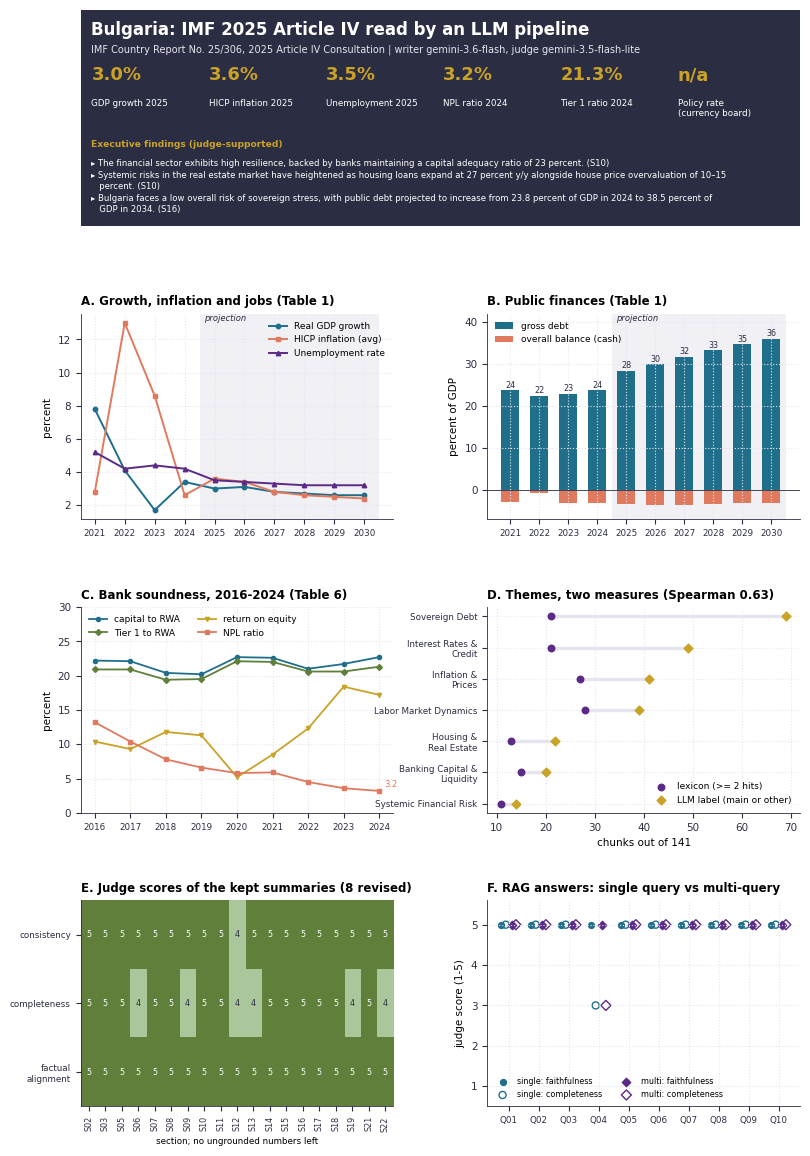

artefacts/figures/dashboard.png


In [23]:
INK, PLUM, PETROL, MUSTARD, CORAL, MOSS, MIST = "#2B2D42", "#5B2A86", "#1F6F8B", "#C9A227", "#E07A5F", "#5F7F3A", "#E6E4EE"
plt.rcParams.update({"font.size": 7.5, "axes.titlesize": 8.5, "axes.titleweight": "bold", "axes.titlelocation": "left",
                     "axes.edgecolor": INK, "axes.linewidth": 0.6, "axes.grid": True, "grid.color": MIST,
                     "grid.linestyle": ":", "grid.linewidth": 0.8, "legend.frameon": False, "legend.fontsize": 6.5,
                     "xtick.color": INK, "ytick.color": INK, "axes.spines.top": False, "axes.spines.right": False})


def trend(name: str) -> pd.DataFrame:
    return long_trends[long_trends.series == name].sort_values("year")


def shade_projection(ax):
    ax.axvspan(FIRST_PROJECTION - 0.5, long_trends.year.max() + 0.5, color=MIST, alpha=0.55, lw=0, zorder=0)
    ax.text(FIRST_PROJECTION - 0.35, ax.get_ylim()[1], "projection", va="top", fontsize=6, color=INK, style="italic")


fig = plt.figure(figsize=(8.27, 11.69))
grid = fig.add_gridspec(4, 2, height_ratios=[1.05, 1, 1, 1], hspace=0.42, wspace=0.3,
                        left=0.105, right=0.975, top=0.988, bottom=0.05)

band = fig.add_subplot(grid[0, :])
band.set_facecolor(INK)
band.grid(False)
band.set_xticks([])
band.set_yticks([])
for side in band.spines.values():
    side.set_visible(False)
band.text(0.015, 0.95, "Bulgaria: IMF 2025 Article IV read by an LLM pipeline", color="white", fontsize=12,
          fontweight="bold", transform=band.transAxes, va="top")
band.text(0.015, 0.84, f"{CFG.report.label} | writer {CFG.models.writer}, judge {CFG.models.judge}",
          color=MIST, fontsize=7, transform=band.transAxes, va="top")
tiles = [("GDP growth 2025", record.gdp_growth_forecast_pct), ("HICP inflation 2025", record.headline_inflation_rate_pct),
         ("Unemployment 2025", record.unemployment_rate_pct), ("NPL ratio 2024", record.non_performing_loan_ratio),
         ("Tier 1 ratio 2024", record.tier_1_capital_ratio), ("Policy rate", record.central_bank_policy_rate_pct)]
for i, (name, val) in enumerate(tiles):
    x = 0.015 + i * 0.163
    band.text(x, 0.74, "n/a" if val is None else f"{val:.1f}%", color=MUSTARD, fontsize=13, fontweight="bold",
              transform=band.transAxes, va="top")
    band.text(x, 0.59, name + ("\n(currency board)" if val is None else ""), color="white", fontsize=6.3,
              transform=band.transAxes, va="top")
lead = [b for b in exec_table.itertuples() if b.supported][:3]
findings = "\n".join(textwrap.fill(f"\u25b8 {b.text} ({b.section_id})", 150, subsequent_indent="   ") for b in lead)
band.text(0.015, 0.40, "Executive findings (judge-supported)", color=MUSTARD, fontsize=6.6, fontweight="bold",
          transform=band.transAxes, va="top")
band.text(0.015, 0.31, findings, color="white", fontsize=6.1, transform=band.transAxes, va="top", linespacing=1.35)

ax = fig.add_subplot(grid[1, 0])
for name, colour, mark, label in [("Real GDP", PETROL, "o", "Real GDP growth"),
                                  ("Consumer price index (HICP, average)", CORAL, "s", "HICP inflation (avg)"),
                                  ("Unemployment rate (percent of labor force)", PLUM, "^", "Unemployment rate")]:
    d = trend(name)
    ax.plot(d.year, d.value, marker=mark, ms=3.2, lw=1.4, color=colour, label=label)
ax.set_title("A. Growth, inflation and jobs (Table 1)")
ax.set_ylabel("percent")
ax.set_xticks(range(2021, 2031))
ax.tick_params(axis="x", labelsize=6.3)
shade_projection(ax)
ax.legend(loc="upper right", ncol=1)

ax = fig.add_subplot(grid[1, 1])
debt, bal = trend("General government gross debt"), trend("General government net lending/borrowing (cash basis)")
ax.bar(debt.year, debt.value, color=PETROL, width=0.62, label="gross debt")
ax.bar(bal.year, bal.value, color=CORAL, width=0.62, label="overall balance (cash)")
ax.axhline(0, color=INK, lw=0.6)
for x, y in zip(debt.year, debt.value):
    ax.text(x, y + 0.6, f"{y:.0f}", ha="center", fontsize=5.8, color=INK)
ax.set_title("B. Public finances (Table 1)")
ax.set_ylabel("percent of GDP")
ax.set_xticks(range(2021, 2031))
ax.tick_params(axis="x", labelsize=6.3)
ax.set_ylim(-7, 42)
shade_projection(ax)
ax.legend(loc="upper left")

ax = fig.add_subplot(grid[2, 0])
for name, colour, mark, label in [("Capital to risk-weighted assets", PETROL, "o", "capital to RWA"),
                                  ("Tier 1 capital to risk-weighted assets", MOSS, "D", "Tier 1 to RWA"),
                                  ("Return on equity", MUSTARD, "v", "return on equity"),
                                  ("Nonperforming loans to total gross loans", CORAL, "s", "NPL ratio")]:
    d = trend(name)
    ax.plot(d.year, d.value, marker=mark, ms=3, lw=1.3, color=colour, label=label)
npl = trend("Nonperforming loans to total gross loans")
ax.annotate(f"{npl.value.iloc[-1]:.1f}", (npl.year.iloc[-1], npl.value.iloc[-1]), xytext=(4, 3),
            textcoords="offset points", fontsize=6, color=CORAL)
ax.set_title("C. Bank soundness, 2016-2024 (Table 6)")
ax.set_ylabel("percent")
ax.set_xticks(range(2016, 2025))
ax.tick_params(axis="x", labelsize=6.3)
ax.legend(loc="upper left", ncol=2)
ax.set_ylim(0, 30)

ax = fig.add_subplot(grid[2, 1])
order = theme_counts.sort_values("llm_any").theme.tolist()
ypos = np.arange(len(order))
lex = theme_counts.set_index("theme").loc[order]
ax.hlines(ypos, lex.lexicon_chunks, lex.llm_any, color=MIST, lw=2.4, zorder=1)
ax.scatter(lex.lexicon_chunks, ypos - 0.0, color=PLUM, marker="o", s=22, label="lexicon (>= 2 hits)", zorder=2)
ax.scatter(lex.llm_any, ypos, color=MUSTARD, marker="D", s=20, label="LLM label (main or other)", zorder=3)
ax.set_yticks(ypos, [t.replace(" & ", " &\n") for t in order], fontsize=6.3)
ax.set_xlabel(f"chunks out of {len(chunks)}")
ax.set_title(f"D. Themes, two measures (Spearman {rho:.2f})")
ax.legend(loc="lower right")

ax = fig.add_subplot(grid[3, 0])
heat = long_scores.pivot(index="criterion", columns="section_id", values="score").loc[
    ["consistency", "completeness", "factual_alignment"]]
im = ax.imshow(heat.values, cmap=plt.matplotlib.colors.ListedColormap([CORAL, "#F2B5A0", "#EAD9A6", "#A9C79A", MOSS]),
               vmin=0.5, vmax=5.5, aspect="auto")
ax.set_xticks(range(heat.shape[1]), heat.columns, rotation=90, fontsize=5.8)
ax.set_yticks(range(3), ["consistency", "completeness", "factual\nalignment"], fontsize=6.3)
ax.grid(False)
for (r, c), v in np.ndenumerate(heat.values):
    ax.text(c, r, f"{v:.0f}", ha="center", va="center", fontsize=5.8, color="white" if v >= 4.5 else INK)
flagged = summaries.loc[summaries.ungrounded.map(bool), "section_id"].tolist()
ax.set_title(f"E. Judge scores of the kept summaries ({int(summaries.revised.sum())} revised)")
ax.set_xlabel("section" + (f"; ungrounded numbers left in {', '.join(flagged)}" if flagged else "; no ungrounded numbers left"),
              fontsize=6.3)

ax = fig.add_subplot(grid[3, 1])
qs = QUESTIONS.qid.tolist()
x = np.arange(len(qs))
for arm, colour, shift, mark in [("single", PETROL, -0.17, "o"), ("multi", PLUM, 0.17, "D")]:
    d = both[both.arm == arm].set_index("qid").loc[qs]
    ax.scatter(x + shift - 0.07, d.faithfulness, color=colour, marker=mark, s=18, label=f"{arm}: faithfulness")   # side by side, so equal scores stay visible
    ax.scatter(x + shift + 0.07, d.completeness, facecolors="none", edgecolors=colour, marker=mark, s=26, label=f"{arm}: completeness")
ax.set_xticks(x, qs, fontsize=6.3)
ax.set_ylim(0.5, 5.6)
ax.set_yticks(range(1, 6))
ax.set_ylabel("judge score (1-5)")
ax.set_title("F. RAG answers: single query vs multi-query")
ax.legend(loc="lower left", ncol=2, fontsize=5.8)

dash_path = OUT / "figures" / "dashboard.png"
fig.savefig(dash_path, dpi=300)
plt.show()
print(dash_path)

### 5.3 Extension figure

This figure compares the three retrieval rankings by gold-page recall, question by question. Beside it are the mean scores and the cost of each arm.

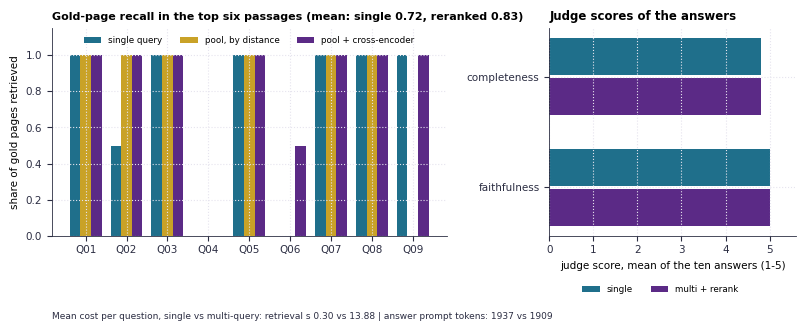

artefacts/figures/extension_retrieval.png


In [24]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(8.27, 3.4), gridspec_kw={"width_ratios": [1.6, 1], "wspace": 0.32})
answerable = QUESTIONS[QUESTIONS.gold_pages.map(len) > 0].qid.tolist()
x = np.arange(len(answerable))
s = both[both.arm == "single"].set_index("qid").loc[answerable]
m = both[both.arm == "multi"].set_index("qid").loc[answerable]
ax1.bar(x - 0.26, s.gold_recall, 0.26, color=PETROL, label="single query")
ax1.bar(x, m.pool_gold_recall, 0.26, color=MUSTARD, label="pool, by distance")
ax1.bar(x + 0.26, m.gold_recall, 0.26, color=PLUM, label="pool + cross-encoder")
ax1.set_xticks(x, answerable)
ax1.set_ylim(0, 1.15)
ax1.set_ylabel("share of gold pages retrieved")
ax1.set_title(f"Gold-page recall in the top six passages (mean: single {compare.gold_recall['single']:.2f}, "
              f"reranked {compare.gold_recall['multi']:.2f})", fontsize=8)
ax1.legend(loc="upper center", ncol=3, fontsize=6.3, bbox_to_anchor=(0.5, 1.0))

metrics = compare.loc[["single", "multi"], ["faithfulness", "completeness"]]   # judge scores only; recall is on the left
ax2.barh(np.arange(2) + 0.18, metrics.loc["single"], 0.34, color=PETROL, label="single")
ax2.barh(np.arange(2) - 0.18, metrics.loc["multi"], 0.34, color=PLUM, label="multi + rerank")
ax2.set_yticks(range(2), ["faithfulness", "completeness"])
ax2.set_xlim(0, 5.6)
ax2.set_xlabel("judge score, mean of the ten answers (1-5)")
ax2.set_title("Judge scores of the answers")
cost = compare.loc[["single", "multi"], ["retrieval_seconds", "prompt_tokens"]]
fig.text(0.08, 0.025, f"Mean cost per question, single vs multi-query: retrieval s {cost.retrieval_seconds['single']:.2f} vs {cost.retrieval_seconds['multi']:.2f} | "
         f"answer prompt tokens: {cost.prompt_tokens['single']:.0f} vs {cost.prompt_tokens['multi']:.0f}",
         fontsize=6.5, color=INK)
ax2.legend(loc="upper center", bbox_to_anchor=(0.45, -0.2), ncol=2, fontsize=6.3)
fig.subplots_adjust(left=0.08, right=0.98, top=0.88, bottom=0.27)
ext_path = OUT / "figures" / "extension_retrieval.png"
fig.savefig(ext_path, dpi=300)
plt.show()
print(ext_path)

## Part 6. Run record

This part writes down what the run did:
- every model call (`call_ledger.json`);
- every prompt template (`prompt_book.json`);
- the hand checks, each with the printed table line it was read from (`hand_checks.json`).

A reader of the report can therefore trace any prompt, count or number back to an output of this notebook.

In [25]:
ledger = pd.DataFrame(LEDGER)
save("call_ledger", {"backend": BACKEND, "calls": len(ledger), "live": int((ledger.source == "live").sum()),
                     "from_cache": int((ledger.source == "cache").sum()), "repairs": int(ledger.repair.sum()),
                     "rows": ledger.to_dict("records")})
save("prompt_book", PROMPTS)
print(f"backend {BACKEND}: {len(ledger)} calls, {int((ledger.source == 'live').sum())} live, "
      f"{int((ledger.source == 'cache').sum())} from cache, {int(ledger.repair.sum())} repair rounds")
ledger.groupby(["role", "model"]).agg(calls=("step", "size"), live=("source", lambda s: int((s == "live").sum())),
                                      mean_seconds=("seconds", "mean"), tokens_in=("tokens_in", "sum"),
                                      tokens_out=("tokens_out", "sum")).round(2)

backend gemini_api: 125 calls, 0 live, 125 from cache, 1 repair rounds


,,calls,live,mean_seconds,tokens_in,tokens_out
role,model,,,,,
judge,gemini-3.5-flash-lite,50,0,0.74,132216,4823
writer,gemini-3.6-flash,75,0,12.41,192906,17006


Each hand-checked number is located on its PDF page. The line printed is the table row the value was read from.

In [26]:
hand_rows = []
for field, (value, year, page, row) in HAND_CHECK.items():
    line = None
    if page is not None:
        line = next((l.strip() for l in pages.set_index("pdf_page").clean[page].split("\n") if l.strip().startswith(row)), None)
        cell = table_value(page, row, year)
        assert cell == value, f"{field}: the hand value {value} is not the printed cell {cell}"
    hand_rows.append({"field": field, "hand_value": value, "year": year, "pdf_page": page, "printed_row": line or row,
                      "pipeline_value": getattr(record, field), "agrees": getattr(record, field) == value})
hand = pd.DataFrame(hand_rows).astype({"pdf_page": "Int64", "year": "Int64"})
save("hand_checks", hand)
for r in hand.itertuples():
    where = "not printed" if pd.isna(r.pdf_page) else f"p.{r.pdf_page}"
    shown = ["null" if pd.isna(v) else v for v in (r.hand_value, r.pipeline_value)]
    print(f"{r.field}: hand {shown[0]} | pipeline {shown[1]} | {where}: {textwrap.shorten(str(r.printed_row), 110)}")

gdp_growth_forecast_pct: hand 3.0 | pipeline 3.0 | p.34: Real GDP 7.8 4.1 1.7 3.4 3.0 3.1 2.8 2.7 2.6 2.6
headline_inflation_rate_pct: hand 3.6 | pipeline 3.6 | p.34: Consumer price index (HICP, average) 2.8 13.0 8.6 2.6 3.6 3.4 2.8 2.6 2.5 2.4
central_bank_policy_rate_pct: hand null | pipeline null | not printed: currency board since 1997, so the BNB sets no policy rate
non_performing_loan_ratio: hand 3.2 | pipeline 3.2 | p.40: Nonperforming loans to total gross loans 13.2 10.4 7.8 6.6 5.8 5.9 4.5 3.6 3.2
unemployment_rate_pct: hand 3.5 | pipeline 3.5 | p.34: Unemployment rate (percent of labor force) 5.2 4.2 4.4 4.2 3.5 3.4 3.3 3.2 3.2 3.2
tier_1_capital_ratio: hand 21.3 | pipeline 21.3 | p.40: Tier 1 capital to risk-weighted assets 20.9 20.9 19.4 19.5 22.1 22.0 20.6 20.6 21.3


Files written by this run:

In [27]:
for f in sorted(OUT.rglob("*.*")):
    print(f"{f.relative_to(OUT)}  {f.stat().st_size / 1024:.1f} KB")

call_ledger.json  27.8 KB
chunks.json  182.0 KB
executive_summary.json  4.1 KB
figures/dashboard.png  684.3 KB
figures/extension_retrieval.png  165.9 KB
hand_checks.json  1.5 KB
indicator_audit.json  2.8 KB
indicators.json  0.2 KB
long_tables.json  27.3 KB
multiquery_vs_single.json  39.3 KB
pages.json  149.2 KB
prompt_book.json  7.9 KB
rag_answers.json  11.5 KB
run_settings.json  0.9 KB
section_summaries.json  37.4 KB
sections.json  149.6 KB
strengths_vulnerabilities.json  7.9 KB
theme_counts.json  1.1 KB
time_series.json  28.3 KB
